# Laboratorio 2
**Redes Neuronales para Lenguaje Natural, 2026**

En este laboratorio construiremos un sistema que, a partir de instrucciones en lenguaje natural, genere programas para dibujar escenas geométricas. Utilizaremos un modelo de lenguaje preentrenado y estudiaremos distintas estrategias para resolver la tarea: **zero-shot, prompting y fine-tuning mediante LoRA**.

**Entrega: 23 de noviembre de 2026**

**Formato: notebook de Python (.ipynb)**

**No olvidar mantener todas las salidas de cada región de código en el notebook!**

---


## 0. Preparación del entorno

Este laboratorio está pensado para ejecutarse en **Google Colab con GPU**:

1. Subí este notebook a Colab (o abrilo desde Drive).
2. `Entorno de ejecución` → `Cambiar tipo de entorno de ejecución` → **T4 GPU**.
3. Ejecutá las celdas de instalación e imports (verificá que imprima el nombre de la GPU).

El `.venv` local es solo para desarrollo en la máquina; **Colab no lo usa**. En Colab las dependencias se instalan con las celdas `%pip` de abajo.

Comenzamos instalando e importando las bibliotecas que utilizaremos a lo largo del laboratorio.


In [1]:
# En algunos entornos Colab viene una versión antigua de torchao que interfiere con PEFT.
%pip uninstall -y torchao

# Dependencias del laboratorio. Qwen3.5 requiere transformers>=5.2.
# En Colab (GPU) usamos la pila pedida por el enunciado; PyTorch CUDA ya viene instalado.
%pip install -q -U pandas matplotlib
%pip install -q -U 'transformers>=5.2,<6' 'accelerate>=1.1,<2' 'peft>=0.18,<1'

import importlib.util
import torch

# Solo en local (sin CUDA): si falta torch o es muy viejo, dejamos un aviso claro.
if not torch.cuda.is_available():
    print('AVISO: no hay GPU CUDA. En Colab elegí Entorno de ejecución → T4 GPU.')
    print('torch:', torch.__version__)
    # Mac Intel (torch 2.2.x): parches opcionales si están en el directorio del notebook.
    major_minor = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])
    if major_minor < (2, 4) and importlib.util.find_spec('patch_transformers_macintel') is not None:
        %run patch_transformers_macintel.py
else:
    print('GPU lista:', torch.cuda.get_device_name(0))


Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
GPU lista: Tesla T4


In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

GRID_SIZE = 6

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no disponible')


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


GPU: Tesla T4


### 0.1. Un lenguaje para dibujar escenas

En lugar de generar directamente una imagen, el modelo deberá producir un programa en un pequeño lenguaje de dominio específico (DSL - Domain-Specific Language). Cada línea describe un objeto de la forma:

```text
FIGURA COLOR X Y TAMAÑO
```

- `FIGURA` puede ser `CIRCLE` (círculo), `SQUARE` (cuadrado) o `TRIANGLE` (triángulo).
- `COLOR` puede ser `RED` (rojo), `BLUE` (azul), `GREEN` (verde) o `YELLOW` (amarillo).
- `X` e `Y` son enteros entre 0 y 5. El origen `(0,0)` está en la esquina superior izquierda. X crece hacia la derecha e Y hacia abajo.
- `TAMAÑO` es un entero entre 1 y 6. Indica que el objeto ocupa una superficie equivalente a un cuadrado de `TAMAÑO x TAMAÑO` celdas.
- `(X,Y)` corresponde a la esquina superior izquierda de esa superficie. La figura crece hacia abajo y hacia la derecha.
- Todos los objetos deben quedar completamente dentro del tablero de 6x6.
- Una escena contiene entre 1 y 3 objetos, y sus superficies no pueden superponerse.

**Importante:** para determinar colisiones, todas las figuras ocupan una superficie cuadrada (que le llamamos "huella"), incluso los círculos y los triángulos.


Por ejemplo:

```text
SQUARE BLUE 1 1 2
CIRCLE RED 3 1 1
```

El cuadrado azul ocupa la región de (1,1) a (2,2), mientras que el círculo rojo ocupa la celda (3,1), como se ve en la siguiente imagen:

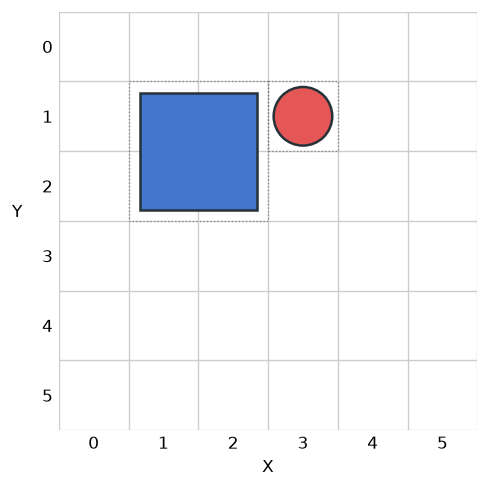


Notar que el orden de las líneas no modifica la escena. Por ese motivo, evaluaremos los dibujos representados, no la igualdad literal entre programas.

Las funciones de interpretación y visualización del DSL se proveen a continuación.


In [3]:
# Una escena es una lista de tuplas (FIGURA, COLOR, X, Y, TAMAÑO).
SHAPES = ('CIRCLE', 'SQUARE', 'TRIANGLE')
COLORS = ('RED', 'BLUE', 'GREEN', 'YELLOW')

COLOR_HEX = {
    'RED': '#e45756',
    'BLUE': '#4277cd',
    'GREEN': '#43a77c',
    'YELLOW': '#e6ba48',
}

class SceneError(ValueError):
    '''La salida no cumple con la gramática o restricciones de la DSL.'''


def validate_scene(scene):
    occupied = set()

    for obj in scene:
        if len(obj) != 5:
            raise SceneError('Cada objeto necesita FIGURA COLOR X Y TAMAÑO.')

        shape, color, x, y, size = obj

        if shape not in SHAPES or color not in COLORS:
            raise SceneError(f'Figura o color desconocidos: {shape} {color}.')

        if any(type(v) is not int for v in (x, y, size)):
            raise SceneError('X, Y y TAMAÑO deben ser enteros.')

        if not (1 <= size <= GRID_SIZE):
            raise SceneError(f'Tamaño inválido: {size}.')

        if x < 0 or y < 0 or x + size > GRID_SIZE or y + size > GRID_SIZE:
            raise SceneError(
                f'Objeto fuera del tablero: ({x}, {y}), tamaño {size}.'
            )

        # Todas las celdas reservadas por el objeto.
        footprint = {
            (col, row)
            for col in range(x, x + size)
            for row in range(y, y + size)
        }

        if occupied & footprint:
            raise SceneError(
                f'Colisión entre objetos en {sorted(occupied & footprint)}.'
            )

        occupied.update(footprint)

    return True


def parse_scene(program):
    '''Convierte el programa DSL en una lista de objetos de cinco atributos.'''
    if not isinstance(program, str) or not program.strip():
        raise SceneError('El programa está vacío.')

    objects = []

    for num, line in enumerate(program.strip().splitlines(), start=1):
        fields = line.strip().split()

        if len(fields) != 5:
            raise SceneError(
                f'Línea {num}: se esperaban 5 campos, '
                f'se recibieron {len(fields)}.'
            )

        shape, color, xs, ys, ss = fields

        try:
            x, y, size = int(xs), int(ys), int(ss)
        except ValueError as e:
            raise SceneError(
                f'Línea {num}: X, Y y TAMAÑO deben ser enteros.'
            ) from e

        objects.append((shape, color, x, y, size))

    validate_scene(objects)
    return objects


def scene_to_dsl(scene):
    '''Serializa en orden estable: Y, X, FIGURA, COLOR, TAMAÑO.'''
    validate_scene(scene)

    ordered = sorted(
        scene,
        key=lambda obj: (obj[3], obj[2], obj[0], obj[1], obj[4])
    )

    return '\n'.join(
        f'{shape} {color} {x} {y} {size}'
        for shape, color, x, y, size in ordered
    )


In [4]:
def render_scene(scene_or_program, ax=None, title=None):
    '''Dibuja una escena con objetos de tamaño variable.'''
    scene = (
        parse_scene(scene_or_program)
        if isinstance(scene_or_program, str)
        else scene_or_program
    )
    validate_scene(scene)

    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))
    else:
        fig = ax.figure

    ax.set_xlim(0, GRID_SIZE)
    ax.set_ylim(GRID_SIZE, 0)
    ax.set_aspect('equal')

    for k in range(GRID_SIZE + 1):
        ax.axvline(k, color='#cccccc', linewidth=0.8, zorder=0)
        ax.axhline(k, color='#cccccc', linewidth=0.8, zorder=0)

    for shape, color, x, y, size in scene:
        cx, cy = x + size / 2, y + size / 2
        margin = 0.08 * size

        kwargs = {
            'facecolor': COLOR_HEX[color],
            'edgecolor': '#263238',
            'linewidth': 1.5,
            'zorder': 2,
        }

        if shape == 'CIRCLE':
            patch = Circle(
                (cx, cy),
                0.42 * size,
                **kwargs
            )

        elif shape == 'SQUARE':
            patch = Rectangle(
                (x + margin, y + margin),
                size - 2 * margin,
                size - 2 * margin,
                **kwargs
            )

        else:
            patch = Polygon(
                [
                    (cx, y + margin),
                    (x + margin, y + size - margin),
                    (x + size - margin, y + size - margin)
                ],
                closed=True,
                **kwargs
            )

        ax.add_patch(patch)

        # Contorno de la superficie reservada por el objeto.
        ax.add_patch(
            Rectangle(
                (x, y),
                size,
                size,
                fill=False,
                edgecolor='#555555',
                linestyle=':',
                linewidth=0.8,
                alpha=0.6,
                zorder=3
            )
        )

    ax.set_xticks(
        [i + 0.5 for i in range(GRID_SIZE)],
        labels=range(GRID_SIZE)
    )
    ax.set_yticks(
        [i + 0.5 for i in range(GRID_SIZE)],
        labels=range(GRID_SIZE)
    )

    ax.tick_params(length=0)
    ax.set_xlabel('X')
    ax.set_ylabel('Y', rotation=0, labelpad=15)

    if title:
        ax.set_title(title)

    for spine in ax.spines.values():
        spine.set_visible(False)

    return fig, ax


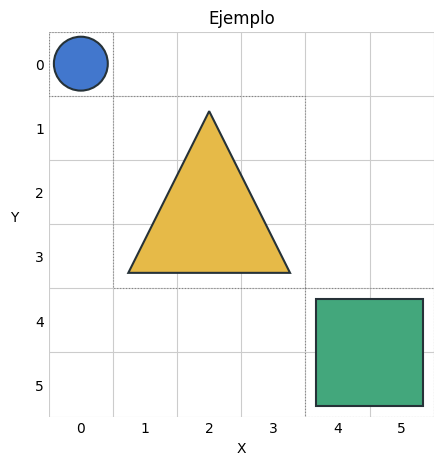

In [5]:
# Ejemplo de un programa renderizado
program = """
CIRCLE BLUE 0 0 1
TRIANGLE YELLOW 1 1 3
SQUARE GREEN 4 4 2
"""

fig, ax = render_scene(program, title='Ejemplo')


### 0.2. Dataset

Trabajaremos con un dataset de 1200 pares `(instrucción, programa)`. Las instrucciones están escritas en español y fueron generadas sintéticamente usando el LLM GPT 6.1 Sol High (OpenAI).

Las particiones se dividen en: 960 ejemplos de entrenamiento (`train`), 120 de desarrollo (`dev`) y 120 de test (`test`).

- `train`: 960 ejemplos, se pueden utilizar para ejemplos few-shot y para hacer fine-tuning.
- `dev`: 120 ejemplos, se pueden utilizar para diseñar prompts, seleccionar hiperparámetros y analizar errores.
- `test`: 120 ejemplos, se reservan para la evaluación final.

Cada dataframe contiene `id`, `instruccion` y `programa` (ground truth).

Además, tendremos el conjunto `test_ood`, que contiene 50 ejemplos con instrucciones muy diferentes a las que se encuentran en los conjuntos anteriores. Hay instrucciones como: _"Hacé una casa de dos piezas: (...) Sumá un sol, círculo amarillo tamaño 1, en (5,0)."_, en las que se describe un escena que representa algo real, e instrucciones como: _"Dibujá seis figuras de una casilla en zigzag..."_, en las que superamos el límite de tres figuras por escena. Este conjunto no lo utilizaremos hasta la parte final del notebook, para medir la capacidad de nuestros métodos para generalizar a escenas fuera de distribución.


In [6]:
#@title Cargar datos del laboratorio

from pathlib import Path
import zipfile

DATASET_ZIP = 'RNLN_2026_lab2_splits.zip'

# En Colab, si el archivo todavía no está, solicitarlo
if not Path(DATASET_ZIP).exists():
    try:
        from google.colab import files
        print('Subí el archivo:', DATASET_ZIP)
        files.upload()
    except ImportError as e:
        raise FileNotFoundError(
            f'No se encontró {DATASET_ZIP}. Colocalo en el directorio de trabajo.'
        ) from e

# Extraer las cuatro particiones
Path('data').mkdir(exist_ok=True)

with zipfile.ZipFile(DATASET_ZIP) as z:
    for split in ('train', 'dev', 'test', 'test_ood'):
        filename = f'data/{split}.csv'
        Path(filename).write_bytes(z.read(filename))

print('Dataset cargado correctamente.')


Subí el archivo: RNLN_2026_lab2_splits.zip


Saving RNLN_2026_lab2_splits.zip to RNLN_2026_lab2_splits.zip
Dataset cargado correctamente.


Train: 960 | Dev: 120 | Test: 120 | Test OOD: 50

Ejemplo de instrucción:
Todo azul: círculo tamaño 1 en el origen, círculo tamaño 2 en (1,1), triángulo tamaño 1 en (4,4).

Programa de referencia:
CIRCLE BLUE 0 0 1
CIRCLE BLUE 1 1 2
TRIANGLE BLUE 4 4 1


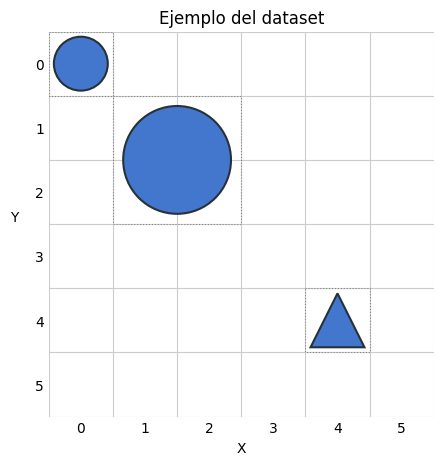

In [7]:
train_df = pd.read_csv('data/train.csv')
dev_df = pd.read_csv('data/dev.csv')
test_df = pd.read_csv('data/test.csv')
test_ood_df = pd.read_csv('data/test_ood.csv')

print('Train:', len(train_df), '| Dev:', len(dev_df), '| Test:', len(test_df), '| Test OOD:', len(test_ood_df))
print('\nEjemplo de instrucción:')
print(train_df.iloc[0]['instruccion'])
print('\nPrograma de referencia:')
print(train_df.iloc[0]['programa'])
render_scene(train_df.iloc[0]['programa'], title='Ejemplo del dataset')
plt.show()


### 0.3. Funciones de evaluación

Utilizaremos las siguientes métricas para comparar los modelos y las estrategias:

- **Validez:** proporción de programas generados que cumplen la gramática y las restricciones del DSL.
- **Accuracy:** proporción de escenas generadas que coinciden exactamente con el dibujo de referencia (sin importar el orden de las líneas).
- **F1 de objetos:** media armónica entre precisión y recall de las tuplas `(FIGURA, COLOR, X, Y, TAMAÑO)`. Una salida inválida recibe F1 = 0.

Se proporciona una función que recibe un dataframe con ejemplos y una lista de predicciones en el mismo orden. También incluimos una función para visualizar las diferencias entre una predicción y la referencia.


In [8]:
def evaluate_predictions(examples_df, predictions):
    if len(examples_df) != len(predictions):
        raise ValueError('Debe haber una predicción por cada instrucción.')
    rows = []
    for (_, row), prediction in zip(examples_df.iterrows(), predictions):
        gold = set(parse_scene(row['programa']))
        valid, exact, f1, error = False, False, 0.0, ''
        try:
            predicted = set(parse_scene(prediction))
            valid = True
            exact = gold == predicted
            f1 = 2 * len(gold & predicted) / (len(gold) + len(predicted))
        except SceneError as e:
            error = str(e)
        rows.append({
            'id': row['id'], 'instruccion': row['instruccion'],
            'referencia': row['programa'], 'prediccion': prediction,
            'valido': valid, 'exacto': exact, 'f1_objetos': f1, 'error': error,
        })
    return pd.DataFrame(rows)


def show_metrics(results, name='Resultados'):
    print(f'{name} (N = {len(results)})')
    print(f'Validez:    {results.valido.mean():.1%}')
    print(f'Accuracy:   {results.exacto.mean():.1%}')
    print(f'F1 objetos: {results.f1_objetos.mean():.3f}')


In [9]:
def compare_drawings(results, index=0):
    row = results.iloc[index]
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
    render_scene(row.referencia, ax=axes[0], title='Referencia')
    if row.valido:
        render_scene(row.prediccion, ax=axes[1], title='Predicción')
    else:
        axes[1].axis('off')
        axes[1].text(0.02, 0.65, 'Generación inválida', fontsize=15,
                     transform=axes[1].transAxes)
        axes[1].text(0.02, 0.4, row.error, fontsize=10,
                     transform=axes[1].transAxes, wrap=True)
    plt.suptitle(row.instruccion, fontsize=10, y=1.03)
    plt.tight_layout()
    plt.show()
    print('PROGRAMA ESPERADO:\n' + row.referencia)
    print('\nPROGRAMA GENERADO:\n' + row.prediccion)


Resultados (N = 1)
Validez:    100.0%
Accuracy:   0.0%
F1 objetos: 0.500


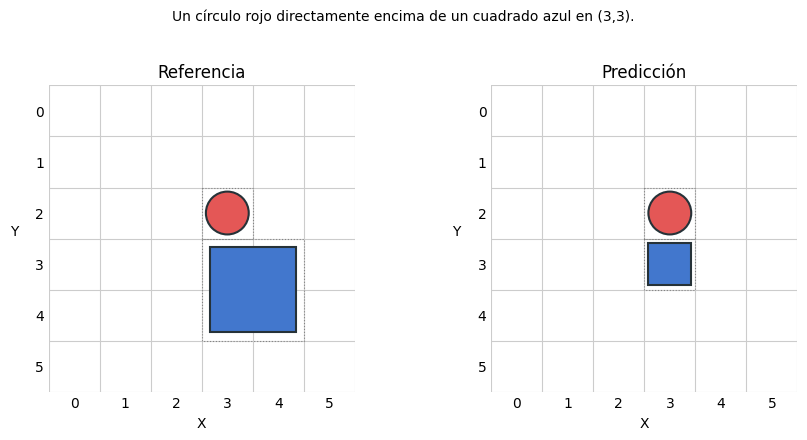

PROGRAMA ESPERADO:

CIRCLE RED 3 2 1
SQUARE BLUE 3 3 2


PROGRAMA GENERADO:

SQUARE BLUE 3 3 1
CIRCLE RED 3 2 1



In [10]:
# Ejemplo de evaluación y comparación entre dos salidas

program_gt = """
CIRCLE RED 3 2 1
SQUARE BLUE 3 3 2
"""

program_pred = """
SQUARE BLUE 3 3 1
CIRCLE RED 3 2 1
"""

example_df = pd.DataFrame({
    'id': [0], 'instruccion': ['Un círculo rojo directamente encima de un cuadrado azul en (3,3).'],
    'programa': [program_gt]
})

results = evaluate_predictions(example_df, [program_pred])
show_metrics(results)
compare_drawings(results)


### 0.4. Modelo de lenguaje

Utilizaremos [Qwen3.5-0.8B](https://huggingface.co/Qwen/Qwen3.5-0.8B), el LLM preentrenado más chico de la familia de modelos Qwen 3.5.

Se proporciona la carga del modelo y una función general para generar una respuesta a partir de una lista de mensajes. Cada mensaje es un diccionario de la forma `{'role': 'system' | 'user' | 'assistant', 'content': texto}`.


In [11]:
import importlib.util
import torch

# Compatibilidad opcional Mac Intel; en Colab este módulo no existe y se ignora.
if importlib.util.find_spec('torch_compat_macintel') is not None:
    import torch_compat_macintel  # noqa: F401

import transformers
import peft
import accelerate
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = 'Qwen/Qwen3.5-0.8B'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
# La T4 de Colab usa FP16; GPUs más nuevas pueden usar BF16.
DTYPE = (
    (torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16)
    if DEVICE == 'cuda'
    else torch.float32
)
print('Modelo:', MODEL_NAME, '| Dispositivo:', DEVICE, '| Precisión:', DTYPE)
print('transformers:', transformers.__version__, '| torch:', torch.__version__)
if DEVICE != 'cuda':
    print('AVISO: sin GPU. En Colab: Entorno de ejecución → T4 GPU, luego reiniciá y reejecutá.')

# En Colab descarga desde Hugging Face la primera vez (necesita red).
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype='auto',
    low_cpu_mem_usage=True,
    device_map='auto' if DEVICE == 'cuda' else None,
)

model = model.to(dtype=DTYPE)
model.eval()
print('Parámetros:', f'{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M')


Modelo: Qwen/Qwen3.5-0.8B | Dispositivo: cuda | Precisión: torch.float16
transformers: 5.22.1 | torch: 2.11.0+cu130


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…): reconstructing file:   0%|          |  0.00B / 1.75GB            

model.safetensors-00001-of-00001.safeten(…): downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Parámetros: 752.4 M


In [12]:
@torch.inference_mode()
def generate_response(messages, max_new_tokens=96):
    """Genera texto a partir de mensajes en formato chat de Hugging Face.

    Ejemplo de formato:
      [{'role': 'user', 'content': 'Hola'}]
    """
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors='pt',
        enable_thinking=False,
    ).to(DEVICE)
    output = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id,
    )
    new_tokens = output[0, inputs['input_ids'].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


In [13]:
# Ejemplo de generación con el LLM
messages = [
    {'role': 'system', 'content': 'Sos un asistente útil.'},
    {'role': 'user', 'content': 'Hola'}
]
print(generate_response(messages))


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


¡Hola! ¿En qué puedo ayudarte hoy? Puedo asistirte en tareas como escribir, traducir, resolver problemas, crear contenido, analizar textos o simplemente conversar. ¿Hay algo específico en mente?


---

## Parte 1: Baseline zero-shot

Utilizando el modelo provisto, construir un sistema que transforme las instrucciones del dataset en programas de nuestro DSL mediante **zero-shot prompting**.

El prompt debe especificar la tarea y el formato esperado. Para cada instrucción, se deberá construir la conversación que se pasa a `generate_response(messages)`, obtener el programa predicho y evaluarlo utilizando las funciones provistas.

**Sugerencias:**
* Describir en el mensaje de sistema la gramática del DSL, las figuras, los colores, las coordenadas, la interpretación del tamaño y las restricciones de límites y colisiones.
* Solicitar únicamente el programa DSL, sin explicaciones ni bloques Markdown.
* Para pruebas rápidas puede utilizar un subconjunto pequeño de `dev`, pero reporte los resultados finales de esta parte sobre todo `dev` (120 ejemplos).

Evaluar la estrategia sobre el corpus de **dev**, imprimiendo validez, accuracy y F1 de objetos. Visualizar al menos **dos ejemplos** con errores y comentar qué fallos se observan.


,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE 2 0 RED 2 0 TRIANGLE 2 0
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE BLUE 4 4\nTRIANGLE RED 1 4 4\nCIRCLE BL...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",FIGURA COLOR X Y TAMAÑO\nTRIANGLE 1 1 2\nCIRCL...
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",CIRCLE 1 1 3\nCIRCLE 1 1 3\nCIRCLE 1 1 3\nCIRC...
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",CIRCLE 1 2 1\nTRIANGLE 1 2 1\nSQUARE 2 3 2
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE 0 0 2\nCIRCLE 0 0 1\nCIRCLE 0 0 2
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",FIGURA COLOR X Y TAMAÑO\nSQUARE RED 3 3\nTRIAN...
117,"Dos figuras de una celda en columna 3, cuadrad...",CIRCLE 3 3 RED\nTRIANGLE 5 5 YELLOW
118,Acomodá en una franja vertical de ancho 2 desd...,FIGURA COLOR X Y TAMAÑO.\nSQUARE RED 2 2\nTRIA...


Baseline Zero-Shot (N = 120)
Validez:    0.8%
Accuracy:   0.8%
F1 objetos: 0.008


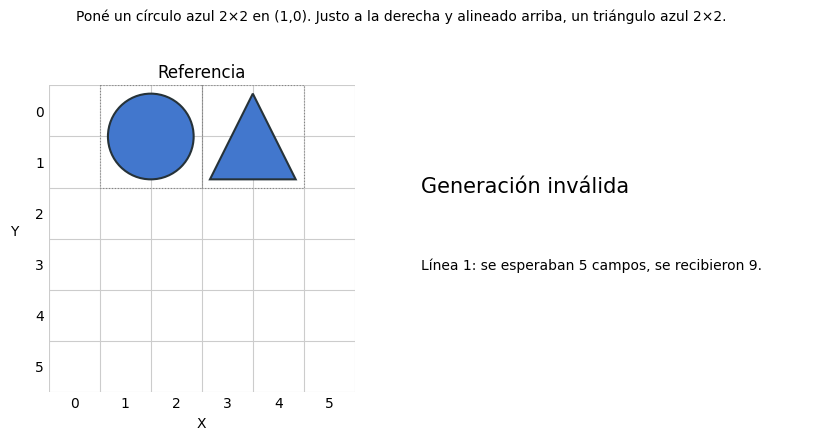

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE 2 0 RED 2 0 TRIANGLE 2 0


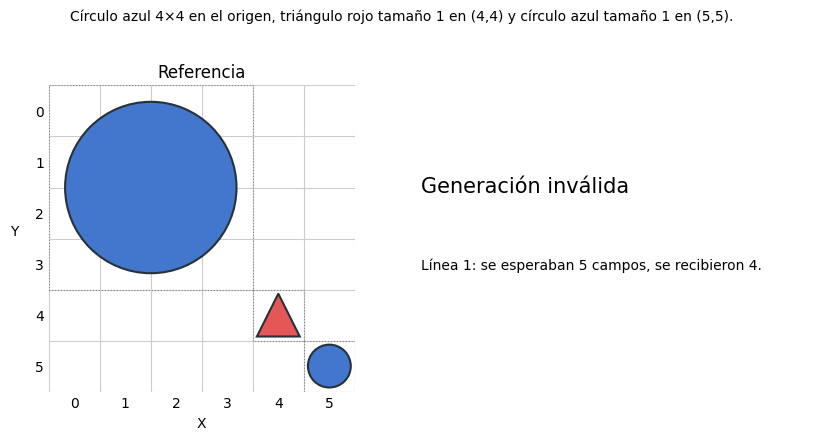

PROGRAMA ESPERADO:
CIRCLE BLUE 0 0 4
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1

PROGRAMA GENERADO:
CIRCLE BLUE 4 4
TRIANGLE RED 1 4 4
CIRCLE BLUE 1 5 5


In [14]:
# TODO (Parte 1):
# 1. Diseñar el prompt zero-shot.

train_zero_llm = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    # print(instruccion_actual)
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO.
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo).
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_zero_llm.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })


df_train_zero_llm = pd.DataFrame(train_zero_llm)
display(df_train_zero_llm)

resultados = evaluate_predictions(dev_df, df_train_zero_llm['programa_generado'])
show_metrics(resultados, name='Baseline Zero-Shot')

# Filtrar índices con errores (no exactos) y visualizar dos ejemplos:
errores_idx = resultados.index[~resultados['exacto']].tolist()
compare_drawings(resultados, index=errores_idx[0])
compare_drawings(resultados, index=errores_idx[1])

# 2. Construir la lista de mensajes para una instrucción.
# 3. Generar predicciones para dev_df (puede empezar con pocos ejemplos).
# 4. Obtener los resultados con evaluate_predictions(...) y show_metrics(...).
# 5. Visualizar errores con compare_drawings(...).


**Descripción del baseline y análisis de resultados:**

(Describa el prompt utilizado, indique las tres métricas y comente los errores observados.)

Aclaracion inicial: el desarrollo de este LAB fue asistido por IA para la construccion del código. Cuando se pudo generar codigo manualmente, eso fue priorizado. Las conclusiones fueron hechas casi sin asistencia de IA.

Se probaron varios prompts, tartando de corregir los errores encontrados con el prompt anterior. Sin embargo los resultados no fueron muy buenos. Los "programas" se asemejaban cada vez mas al programa esperado, pero siembre se encontraron errores que hicieron que el programa no sea exactamente como se esperaba. Alguno de las lineas del programa se ajustaba a lo esperado, pero no logramos que todas lo hicieran.


---

## Parte 2: Estrategias de prompting

Diseñar y evaluar al menos **tres estrategias diferentes de prompting** adicionales al baseline de la Parte 1. Para cada una, describir la idea, implementar la estrategia, evaluarla en `dev` y comparar los resultados con zero-shot.

Se **recomienda que al menos una de las estrategias sea few-shot prompting**: incluir ejemplos resueltos tomados de `train` en los mensajes que recibe el modelo. Las otras dos estrategias quedan a elección.

**Posibles alternativas para explorar:**
* Variar la cantidad o selección de ejemplos few-shot, sin utilizar `dev` ni `test` para las demostraciones.
* Mejorar las reglas, instrucciones y organización del prompt de sistema.
* Diseñar un procedimiento de generación y corrección: por ejemplo, verificar si la salida cumple el DSL y solicitar una nueva generación cuando sea inválida.
* También es válido variar aspectos como el modelo, parámetros del decoding, razonamiento, utilizar generación estructurada, o realizar múltiples llamadas al modelo.

Se debe reportar una tabla comparativa entre el baseline zero-shot y las nuevas estrategias, e identificar la mejor configuración utilizando **accuracy en `dev`**. Analizar también la validez y F1 de objetos.


### Estrategia 1

Describa aquí la estrategia de prompting que quiere probar. Se recomienda comenzar con few-shot prompting.


,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE BLUE 0 0 1\nTRIANGLE BLUE 1 1 2
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE RED 0 0 1\nCIRCLE BLUE 4 4 1\nTRIANGLE ...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",TRIANGLE YELLOW 0 3 2\nCIRCLE YELLOW 0 3 3
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",TRIANGLE YELLOW 1 1 3 TRIANGLE RED 1 5 1
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",SQUARE GREEN 1 2 1\nTRIANGLE BLUE 1 3 1\nSQUAR...
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE GREEN 3 2 2 1 2 4
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",SQUARE YELLOW 2 1 3\nTRIANGLE 1 4 1\nTRIANGLE ...
117,"Dos figuras de una celda en columna 3, cuadrad...",SQUARE GREEN 3 3 TRIANGLE YELLOW 5 5 1 2 3 4 5...
118,Acomodá en una franja vertical de ancho 2 desd...,SQUARE YELLOW 3 0 2\nTRIANGLE BLUE 3 2 2\nCIRC...


Estrategia 1: One-Shot (N = 120)
Validez:    48.3%
Accuracy:   15.0%
F1 objetos: 0.256


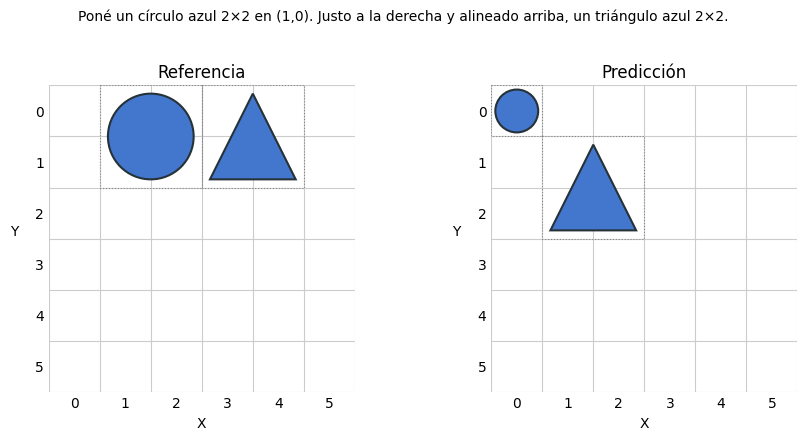

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE BLUE 0 0 1
TRIANGLE BLUE 1 1 2


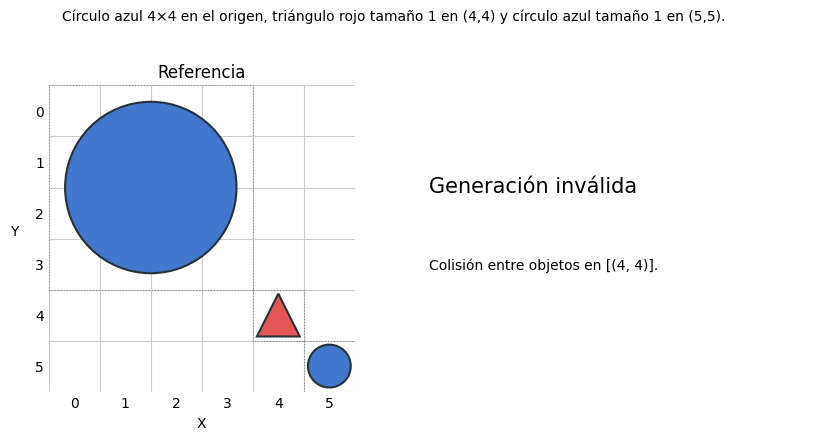

PROGRAMA ESPERADO:
CIRCLE BLUE 0 0 4
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1

PROGRAMA GENERADO:
CIRCLE RED 0 0 1
CIRCLE BLUE 4 4 1
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1


In [15]:
# TODO (Estrategia 1): implementar el prompt y generar/evaluar sobre dev_df.
# ONE SHOT
one_shot_example = {
    'instruccion': 'Colocá un círculo rojo en la esquina superior izquierda.',
    'programa': 'CIRCLE RED 0 0 1'
}

train_llm_one_shot = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    # print(instruccion_actual)
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO.
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo).
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': one_shot_example['instruccion']},
        {'role': 'assistant', 'content': one_shot_example['programa']},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_llm_one_shot.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })

    # print('\nPrograma generado:')
    # print(programa_generado)
    # print('\nPrograma de referencia:')
    # print(dev_df.iloc[i]['programa'])


df_train_llm_one_shot = pd.DataFrame(train_llm_one_shot)
display(df_train_llm_one_shot)

resultados_one_shot = evaluate_predictions(dev_df, df_train_llm_one_shot['programa_generado'])
show_metrics(resultados_one_shot, name='Estrategia 1: One-Shot')

errores_idx_os = resultados_one_shot.index[~resultados_one_shot['exacto']].tolist()
if len(errores_idx_os) >= 2:
    compare_drawings(resultados_one_shot, index=errores_idx_os[0])
    compare_drawings(resultados_one_shot, index=errores_idx_os[1])


**Resultados y observaciones (estrategia 1): One Shot**

Aqui los resultados mejoraron notoriamente frente a la estrategia Zero-Shot.
Se agrego al prompt, en modo assistant,  1 ejemplo de pregunta/respuesta que guió al LLM a mejor performance.

Estrategia 1: One-Shot (N = 120)
Validez:    48.3%
Accuracy:   15.0%
F1 objetos: 0.256

### Estrategia 2

Describa la nueva estrategia y cómo se diferencia de las anteriores.


,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE BLUE 1 0 2\nTRIANGLE BLUE 1 1 2
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE BLUE 4 4 1\nTRIANGLE RED 4 4 1\nCIRCLE ...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",TRIANGLE YELLOW 2 3 2\nCIRCLE YELLOW 3 3 3
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",TRIANGLE YELLOW 2 2 3\nTRIANGLE YELLOW 2 2 1\n...
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",SQUARE GREEN 1 1 1\nTRIANGLE BLUE 1 2 1\nSQUAR...
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE GREEN 3 2 2\nCIRCLE GREEN 3 4 1
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",SQUARE YELLOW 3 3 2 1 TRIANGLE RED 4 4 1 TRIAN...
117,"Dos figuras de una celda en columna 3, cuadrad...",SQUARE GREEN 3 3 2\nTRIANGLE YELLOW 3 5 3
118,Acomodá en una franja vertical de ancho 2 desd...,SQUARE YELLOW 2 2 2\nTRIANGLE BLUE 2 2 2\nCIRC...


Estrategia 2: Few-Shot (3 ejemplos) (N = 120)
Validez:    57.5%
Accuracy:   25.8%
F1 objetos: 0.351


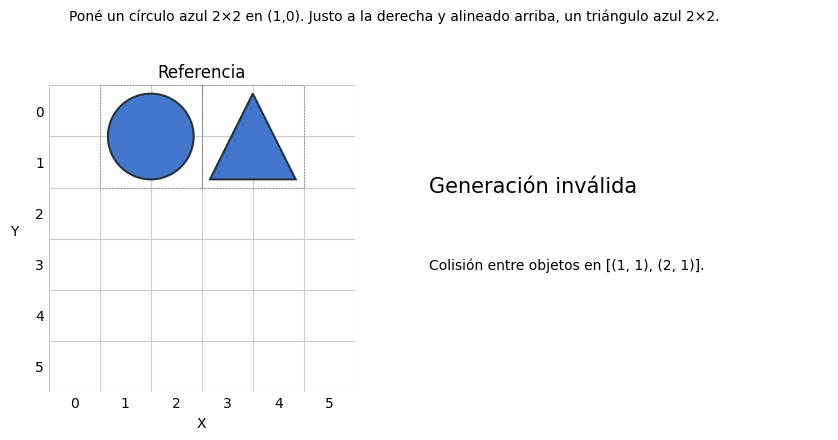

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 1 1 2


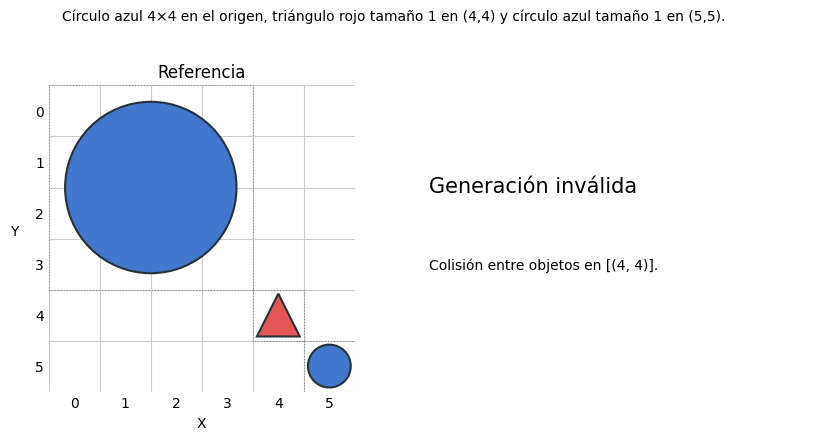

PROGRAMA ESPERADO:
CIRCLE BLUE 0 0 4
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1

PROGRAMA GENERADO:
CIRCLE BLUE 4 4 1
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1


In [16]:
# TODO (Estrategia 2): implementar el prompt y generar/evaluar sobre dev_df. FEW SHOT
few_shot_examples = [
    {
        'instruccion': 'Colocá un círculo rojo en el origen.',
        'programa': 'CIRCLE RED 0 0 1'
    },
    {
        'instruccion': 'Colocá un cuadrado azul de tamaño 2 en la esquina inferior derecha.',
        'programa': 'SQUARE BLUE 4 4 2'
    },
    {
        'instruccion': 'Colocá un triángulo verde de tamaño 3 en el centro.',
        'programa': 'TRIANGLE GREEN 2 2 3'
    }
]

train_llm_few_shot = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    # print(instruccion_actual)
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO.
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo).
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': few_shot_examples[0]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples[0]['programa']},
        {'role': 'user', 'content': few_shot_examples[1]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples[1]['programa']},
        {'role': 'user', 'content': few_shot_examples[2]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples[2]['programa']},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_llm_few_shot.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })

df_train_llm_few_shot = pd.DataFrame(train_llm_few_shot)
display(df_train_llm_few_shot)

resultados_few_shot = evaluate_predictions(dev_df, df_train_llm_few_shot['programa_generado'])
show_metrics(resultados_few_shot, name='Estrategia 2: Few-Shot (3 ejemplos)')

errores_idx_fs = resultados_few_shot.index[~resultados_few_shot['exacto']].tolist()
if len(errores_idx_fs) >= 2:
    compare_drawings(resultados_few_shot, index=errores_idx_fs[0])
    compare_drawings(resultados_few_shot, index=errores_idx_fs[1])


**Resultados y observaciones (estrategia 2): Few-Shot**
Aqui los resultados mejoraron notoriamente frente a la estrategia One-shot.
Se agrego al prompt, en modo assistant,  3 ejemplos de pregunta/respuesta que guió al LLM a mejor performance.

Estrategia 1: One-Shot (N = 120)
Validez:    48.3%
Accuracy:   15.0%
F1 objetos: 0.256

Estrategia 2: Few-Shot (3 ejemplos) (N = 120)
Validez:    57.5%
Accuracy:   25.8%
F1 objetos: 0.351


### Estrategia 3

Describa la nueva estrategia y cómo se diferencia de las anteriores.


,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE BLUE 1 0 2\nTRIANGLE BLUE 1 0 2
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE BLUE 0 0 4\nTRIANGLE RED 4 4 1\nCIRCLE ...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",TRIANGLE YELLOW 0 3 2 SQUARE YELLOW 0 3 3
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",TRIANGLE YELLOW 1 1 3\nTRIANGLE RED 5 5 1\nSQU...
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",SQUARE GREEN 1 2 1\nTRIANGLE BLUE 2 3 1\nSQUAR...
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE GREEN 3 2 2\nCIRCLE GREEN 3 4 1
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",SQUARE YELLOW 2 1 3\nTRIANGLE GREEN 2 1 1\nTRI...
117,"Dos figuras de una celda en columna 3, cuadrad...",CIRCLE RED 3 0 1\nSQUARE BLUE 3 3 2\nTRIANGLE ...
118,Acomodá en una franja vertical de ancho 2 desd...,SQUARE YELLOW 3 0 2 TRIANGLE BLUE 3 2 2 CIRCLE...


Estrategia 3: Chain of Thought (N = 120)
Validez:    62.5%
Accuracy:   49.2%
F1 objetos: 0.547


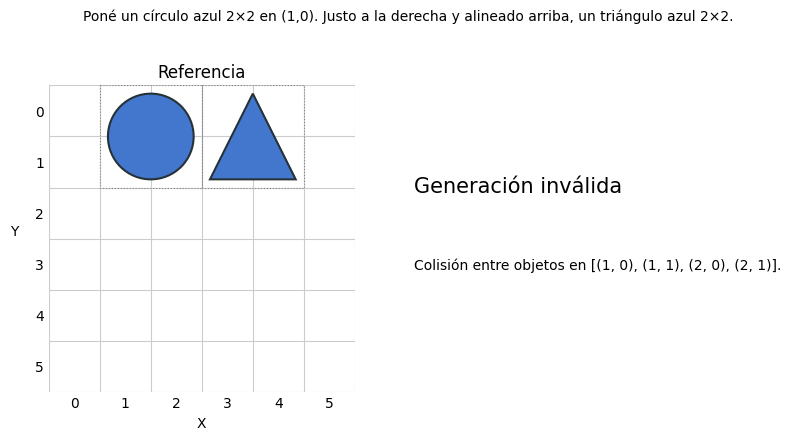

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 1 0 2


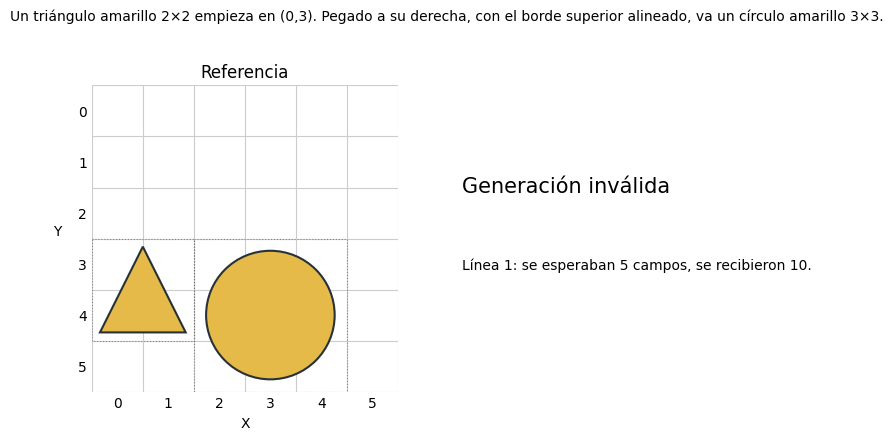

PROGRAMA ESPERADO:
TRIANGLE YELLOW 0 3 2
CIRCLE YELLOW 2 3 3

PROGRAMA GENERADO:
TRIANGLE YELLOW 0 3 2 SQUARE YELLOW 0 3 3


In [17]:
# TODO (Estrategia 3): implementar el prompt y generar/evaluar sobre dev_df. Chain of Thought (CoT)
cot_examples = [
    {
        'instruccion': 'Colocá un círculo rojo en el origen.',
        'razonamiento': 'El origen tiene coordenadas (0,0). Queremos un círculo rojo de tamaño 1.',
        'programa': 'CIRCLE RED 0 0 1'
    },
    {
        'instruccion': 'Colocá un cuadrado azul de tamaño 2 en la esquina inferior derecha.',
        'razonamiento': 'La esquina inferior derecha tiene coordenadas (4,4). Queremos un cuadrado azul de tamaño 2.',
        'programa': 'SQUARE BLUE 4 4 2'
    },
    {
        'instruccion': 'Colocá un triángulo verde de tamaño 3 en el centro.',
        'razonamiento': 'El centro tiene coordenadas (2,2). Queremos un triángulo verde de tamaño 3.',
        'programa': 'TRIANGLE GREEN 2 2 3'
    }
]

train_llm_cot = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO.
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo).
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': cot_examples[0]['instruccion']},
        {'role': 'assistant', 'content': cot_examples[0]['razonamiento']},
        {'role': 'assistant', 'content': cot_examples[0]['programa']},
        {'role': 'user', 'content': cot_examples[1]['instruccion']},
        {'role': 'assistant', 'content': cot_examples[1]['razonamiento']},
        {'role': 'assistant', 'content': cot_examples[1]['programa']},
        {'role': 'user', 'content': cot_examples[2]['instruccion']},
        {'role': 'assistant', 'content': cot_examples[2]['razonamiento']},
        {'role': 'assistant', 'content': cot_examples[2]['programa']},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_llm_cot.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })

df_train_llm_cot = pd.DataFrame(train_llm_cot)
display(df_train_llm_cot[['instruccion', 'programa_generado']])

resultados_cot = evaluate_predictions(dev_df, df_train_llm_cot['programa_generado'])
show_metrics(resultados_cot, name='Estrategia 3: Chain of Thought')

errores_idx_cot = resultados_cot.index[~resultados_cot['exacto']].tolist()
if len(errores_idx_cot) >= 2:
    compare_drawings(resultados_cot, index=errores_idx_cot[0])
    compare_drawings(resultados_cot, index=errores_idx_cot[1])


**Resultados y observaciones (estrategia 3):implementar el prompt y generar/evaluar sobre dev_df. Chain of Thought (CoT)**

Aqui los resultados mejoraron notoriamente frente a la estrategia One-shot y frente a few shot.
Se agrego al prompt, en modo assistant,  3 ejemplos de pregunta/ razonamiento /respuesta que guió al LLM a mejor performance.

Estrategia 1: One-Shot (N = 120)
Validez:    48.3%
Accuracy:   15.0%
F1 objetos: 0.256

Estrategia 2: Few-Shot (3 ejemplos) (N = 120)
Validez:    57.5%
Accuracy:   25.8%
F1 objetos: 0.351

Estrategia 3: Chain of Thought (N = 120)
Validez:    62.5%
Accuracy:   49.2%
F1 objetos: 0.547


### Estrategia 4


Describa la nueva estrategia y cómo se diferencia de las anteriores.

,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE BLUE 1 0 2\nTRIANGLE BLUE 1 0 2
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE BLUE 0 0 4\nTRIANGLE RED 4 4 1\nCIRCLE ...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",TRIANGLE YELLOW 0 3 2\nCIRCLE YELLOW 0 3 3
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",TRIANGLE YELLOW 1 1 3\nTRIANGLE YELLOW 4 4 1\n...
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",SQUARE GREEN 1 2 1\nTRIANGLE BLUE 2 3 1\nSQUAR...
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE GREEN 3 2 2\nCIRCLE GREEN 3 4 1
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",SQUARE YELLOW 3 1 3\nTRIANGLE YELLOW 4 4 1\nTR...
117,"Dos figuras de una celda en columna 3, cuadrad...",SQUARE GREEN 3 3 3\nTRIANGLE YELLOW 5 5 1
118,Acomodá en una franja vertical de ancho 2 desd...,SQUARE YELLOW 2 0 2\nTRIANGLE BLUE 2 2 2\nCIRC...


Estrategia 4: Few-Shot (3 ejemplos de train df) (N = 120)
Validez:    75.8%
Accuracy:   53.3%
F1 objetos: 0.603


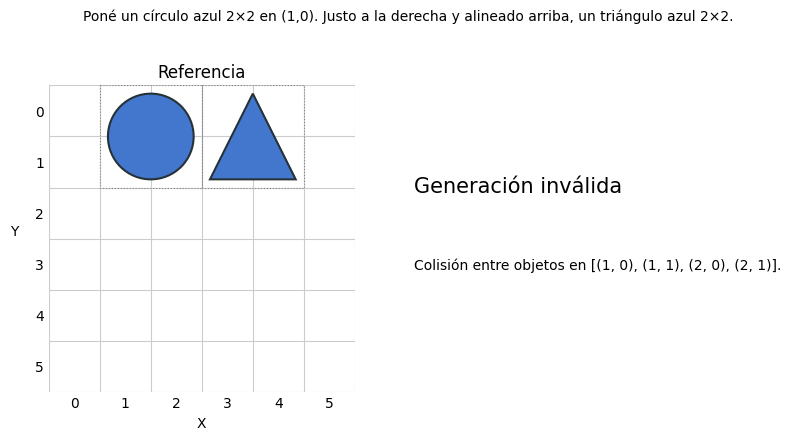

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 1 0 2


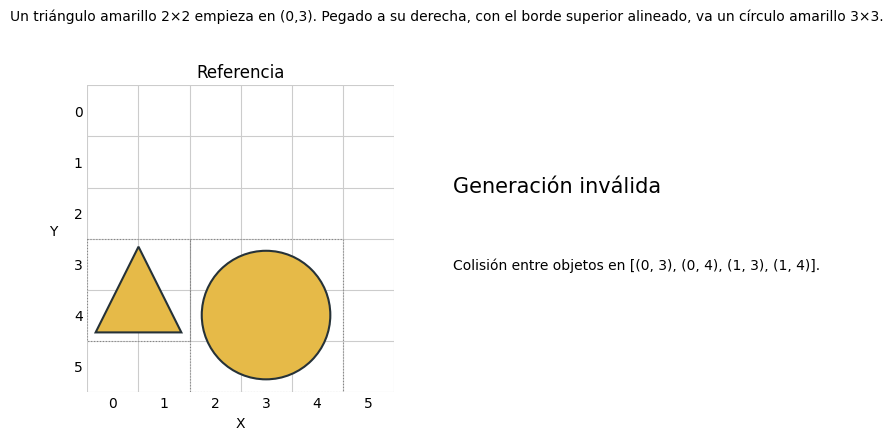

PROGRAMA ESPERADO:
TRIANGLE YELLOW 0 3 2
CIRCLE YELLOW 2 3 3

PROGRAMA GENERADO:
TRIANGLE YELLOW 0 3 2
CIRCLE YELLOW 0 3 3


In [18]:
# Estrategia 4 Few shot usando ejemplos de Dataset de Training
few_shot_examples_train = [
    {
        'instruccion': train_df.iloc[0]['instruccion'],
        'programa': train_df.iloc[0]['programa']
    },
    {
        'instruccion': train_df.iloc[1]['instruccion'],
        'programa': train_df.iloc[1]['programa']
    },
    {
        'instruccion': train_df.iloc[2]['instruccion'],
        'programa': train_df.iloc[2]['programa']
    }
]

train_llm_few_shot_train = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    # print(instruccion_actual)
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO.
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo).
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': few_shot_examples_train[0]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples_train[0]['programa']},
        {'role': 'user', 'content': few_shot_examples_train[1]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples_train[1]['programa']},
        {'role': 'user', 'content': few_shot_examples_train[2]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples_train[2]['programa']},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_llm_few_shot_train.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })

df_train_llm_few_shot_train = pd.DataFrame(train_llm_few_shot_train)
display(df_train_llm_few_shot_train)

resultados_few_shot_train = evaluate_predictions(dev_df, df_train_llm_few_shot_train['programa_generado'])
show_metrics(resultados_few_shot_train, name='Estrategia 4: Few-Shot (3 ejemplos de train df)')

errores_idx_fs = resultados_few_shot_train.index[~resultados_few_shot_train['exacto']].tolist()
if len(errores_idx_fs) >= 2:
    compare_drawings(resultados_few_shot_train, index=errores_idx_fs[0])
    compare_drawings(resultados_few_shot_train, index=errores_idx_fs[1])


**Resultados y observaciones (estrategia 4):Few shot usando ejemplos de Dataset de Training**

Aqui los resultados mejoraron notoriamente frente a la estrategia las demas estrategias.  
Se agrego al prompt, en modo assistant,  3 ejemplos de pregunta/respuesta usando 3 pares de preguntas/respuestas del data set de train.

Estrategia 1: One-Shot (N = 120)
Validez:    48.3%
Accuracy:   15.0%
F1 objetos: 0.256

Estrategia 2: Few-Shot (3 ejemplos) (N = 120)
Validez:    57.5%
Accuracy:   25.8%
F1 objetos: 0.351

Estrategia 3: Chain of Thought (N = 120)
Validez:    62.5%
Accuracy:   49.2%
F1 objetos: 0.550

Estrategia 4: Few-Shot (3 ejemplos de train df) (N = 120)
Validez:    75.8%
Accuracy:   52.5%
F1 objetos: 0.603

Éstos fueron los mejores resultados obtenidos.


### Comparación de las estrategias

Construya una tabla con las métricas obtenidas por las alternativas exploradas (zero-shot y las nuevas estrategias), e incluya el análisis de al menos **dos errores** de su mejor estrategia.


,Validez (%),Accuracy (%),F1 objetos
Estrategia,,,
Baseline Zero-Shot,0.8,0.8,0.008
Estrategia 1: One-Shot,48.3,15.0,0.256
Estrategia 2: Few-Shot (3 ej. manuales),57.5,25.8,0.351
Estrategia 3: Chain of Thought (CoT),62.5,49.2,0.547
Estrategia 4: Few-Shot (3 ej. de train),75.8,53.3,0.603



Mejor estrategia: Estrategia 4: Few-Shot (3 ej. de train)
Total de errores en Estrategia 4: Few-Shot (3 ej. de train): 56 (29 inválidos, 27 válidos pero inexactos)

--- Ejemplo con error (índice dev=0, id=size_scene_0483, válido=False) ---


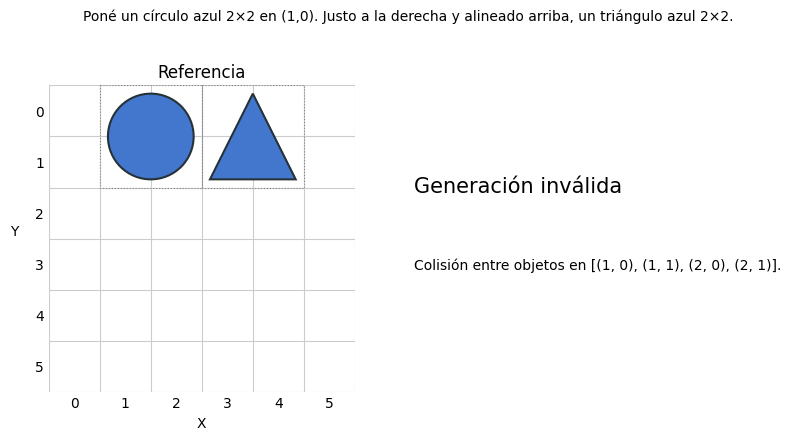

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 1 0 2
--- Ejemplo con error (índice dev=5, id=size_scene_0802, válido=True) ---


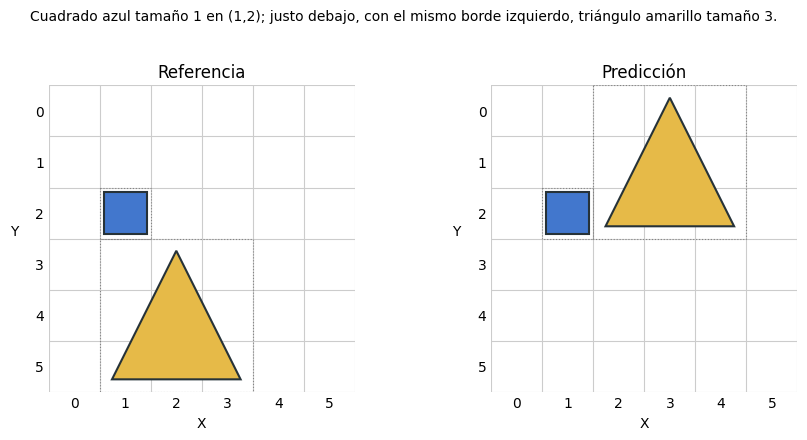

PROGRAMA ESPERADO:
SQUARE BLUE 1 2 1
TRIANGLE YELLOW 1 3 3

PROGRAMA GENERADO:
SQUARE BLUE 1 2 1
TRIANGLE YELLOW 2 0 3
--- Ejemplo con error (índice dev=7, id=size_scene_0010, válido=True) ---


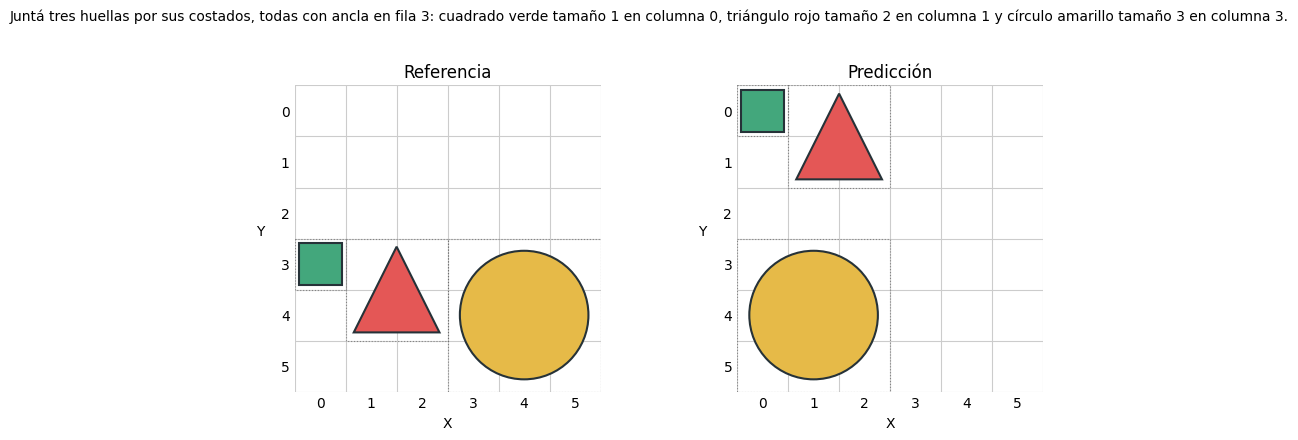

PROGRAMA ESPERADO:
SQUARE GREEN 0 3 1
TRIANGLE RED 1 3 2
CIRCLE YELLOW 3 3 3

PROGRAMA GENERADO:
CIRCLE YELLOW 0 3 3
TRIANGLE RED 1 0 2
SQUARE GREEN 0 0 1


In [19]:
# Construir la tabla de resultados de la Parte 1 y las 4 nuevas estrategias
import sys
if not hasattr(sys.stdout, "pub_thread") and hasattr(sys.stderr, "pub_thread"):
    from ipykernel.iostream import OutStream
    sys.stdout = OutStream(sys.stderr.session, sys.stderr.pub_thread, "stdout")

experimentos = [
    ("Baseline Zero-Shot", resultados),
    ("Estrategia 1: One-Shot", resultados_one_shot),
    ("Estrategia 2: Few-Shot (3 ej. manuales)", resultados_few_shot),
    ("Estrategia 3: Chain of Thought (CoT)", resultados_cot),
    ("Estrategia 4: Few-Shot (3 ej. de train)", resultados_few_shot_train),
]

filas_comparativas = []
for nombre, df_res in experimentos:
    filas_comparativas.append({
        "Estrategia": nombre,
        "Validez (%)": round(df_res["valido"].mean() * 100, 1),
        "Accuracy (%)": round(df_res["exacto"].mean() * 100, 1),
        "F1 objetos": round(df_res["f1_objetos"].mean(), 3),
    })

df_comparativo = pd.DataFrame(filas_comparativas).set_index("Estrategia")
display(df_comparativo)

# Identificar la mejor estrategia (mayor Validez y Accuracy: Estrategia 4)
mejor_nombre, mejor_res = max(
    experimentos,
    key=lambda x: (x[1]["valido"].mean(), x[1]["exacto"].mean())
)
print(f"\nMejor estrategia: {mejor_nombre}")

# Visualizar errores de la mejor estrategia:
# 1) Errores de colisión/sintaxis (inválidos) y 2) Errores con programa válido pero escena inexacta
errores_invalidos = mejor_res.index[~mejor_res["valido"]].tolist()
errores_validos = mejor_res.index[mejor_res["valido"] & ~mejor_res["exacto"]].tolist()

print(f"Total de errores en {mejor_nombre}: {len(errores_invalidos) + len(errores_validos)} "
      f"({len(errores_invalidos)} inválidos, {len(errores_validos)} válidos pero inexactos)\n")

# Mostramos un error inválido (colisión) y dos errores con programa válido pero escena incorrecta
for idx in (errores_invalidos[:1] + errores_validos[:2]):
    print(f"--- Ejemplo con error (índice dev={idx}, id={mejor_res.loc[idx, 'id']}, válido={mejor_res.loc[idx, 'valido']}) ---")
    compare_drawings(mejor_res, index=idx)

**Análisis comparativo:**

Los mejores resultados fueron los obtenidos en la estrategia 4.

	                                    Validez (%)	Accuracy (%)	F1 objetos
Estrategia
Baseline Zero-Shot	                    0.0	        0.0	            0.000
Estrategia 1: One-Shot                  48.3%       15.0%           0.256
Estrategia 2: Few-Shot                  57.5%       25.8%           0.351
Estrategia 3: Chain of Thought (CoT)	  62.5%	      49.2%	          0.550
Estrategia 4: Few-Shot (3 ej. de train)	75.8%	      52.5%	          0.603

La validez de los programas es muy buena, sin embargo la accuracy todavia apenas supera el 50%.
Posiblemente si elijo mas cuidadosamente los ejemplos del few shot para que contemplen mas "casos diferentes" va a mejorar la performance general.

---

## Parte 3: Fine-tuning mediante LoRA

Utilizando `train`, realizar un **fine-tuning supervisado de Qwen3.5-0.8B con LoRA** para adaptar el modelo a la tarea de generación de programas DSL.

El entrenamiento deberá utilizar los pares `(instruccion, programa)` de `train`: la entrada del usuario es la instrucción en español y la respuesta esperada del asistente es el programa DSL correspondiente.

**Sugerencias:**
* Utilizar [`LoraConfig` y `get_peft_model`](https://huggingface.co/docs/peft/main/package_reference/lora) de PEFT para adaptar el modelo y [`Trainer` / `TrainingArguments`](https://huggingface.co/docs/transformers/main/main_classes/trainer) para el entrenamiento supervisado.
* En Qwen3.5, `target_modules='all-linear'` permite seleccionar proyecciones lineales sin depender de los nombres internos de las capas.
* Utilizar un prompt de entrenamiento consistente con el que se utilizará para generar durante la evaluación.


### 3.1. Preparación de los datos supervisados

Construya los ejemplos de entrenamiento con el chat template del tokenizador.


In [20]:
# 3.1. Preparación de los datos supervisados:
# 1) Configurar tokenizador
# 2) Aplicar chat template (con enable_thinking=False consistente con generate_response)
# 3) Formatear dataset conversacional (enmascarando el prompt con -100 en labels para supervisar solo la respuesta del asistente)

from torch.utils.data import Dataset

# Asegurar configuración del tokenizador para entrenamiento y padding
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

SYSTEM_PROMPT_LORA = (
    """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO.
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo).
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)
        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """
)


def build_messages(instruccion: str, programa: str | None = None) -> list[dict[str, str]]:
    """Construye la estructura conversacional para entrenamiento o inferencia."""
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT_LORA},
        {"role": "user", "content": instruccion.strip()},
    ]
    if programa is not None:
        messages.append({"role": "assistant", "content": programa.strip()})
    return messages


class DSLConversationalDataset(Dataset):
    """Dataset conversacional formateado con el chat template de Qwen."""

    def __init__(self, df: pd.DataFrame, tokenizer, max_length: int = 256):
        self.samples = []
        for _, row in df.iterrows():
            prompt_msgs = build_messages(row["instruccion"])
            full_msgs = build_messages(row["instruccion"], row["programa"])

            # Texto del prompt (hasta el inicio de la respuesta del asistente) y conversación completa
            prompt_text = tokenizer.apply_chat_template(
                prompt_msgs,
                tokenize=False,
                add_generation_prompt=True,
                enable_thinking=False,
            )
            full_text = tokenizer.apply_chat_template(
                full_msgs,
                tokenize=False,
                add_generation_prompt=False,
                enable_thinking=False,
            )

            prompt_ids = tokenizer(
                prompt_text, add_special_tokens=False
            )["input_ids"]
            full_enc = tokenizer(
                full_text,
                add_special_tokens=False,
                truncation=True,
                max_length=max_length,
            )

            input_ids = full_enc["input_ids"]
            attention_mask = full_enc["attention_mask"]

            # Enmascarar con -100 los tokens del prompt para calcular la pérdida solo sobre el programa DSL
            prompt_len = min(len(prompt_ids), len(input_ids))
            labels = [-100] * prompt_len + input_ids[prompt_len:]

            self.samples.append({
                "input_ids": input_ids,
                "attention_mask": attention_mask,
                "labels": labels,
            })

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int) -> dict[str, list[int]]:
        return self.samples[idx]


def collate_conversational_batch(batch: list[dict[str, list[int]]]) -> dict[str, torch.Tensor]:
    """Aplica padding dinámico a input_ids, attention_mask y labels (-100)."""
    max_len = max(len(item["input_ids"]) for item in batch)
    pad_id = tokenizer.pad_token_id

    input_ids, attention_mask, labels = [], [], []
    for item in batch:
        pad_len = max_len - len(item["input_ids"])
        input_ids.append(item["input_ids"] + [pad_id] * pad_len)
        attention_mask.append(item["attention_mask"] + [0] * pad_len)
        labels.append(item["labels"] + [-100] * pad_len)

    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long),
    }


train_dataset = DSLConversationalDataset(train_df, tokenizer, max_length=1024)
dev_dataset = DSLConversationalDataset(dev_df, tokenizer, max_length=1024)

max_seq_len = max(len(s["input_ids"]) for s in train_dataset)
min_sup_tokens = min(sum(1 for x in s["labels"] if x != -100) for s in train_dataset)
print(f"Ejemplos de entrenamiento: {len(train_dataset)} | Validación (dev): {len(dev_dataset)}")
print(f"Longitud máxima de secuencia en train: {max_seq_len} tokens | Mínimo de tokens supervisados (labels != -100): {min_sup_tokens}")

ejemplo_texto = tokenizer.apply_chat_template(
    build_messages(train_df.iloc[0]["instruccion"], train_df.iloc[0]["programa"]),
    tokenize=False,
    add_generation_prompt=False,
    enable_thinking=False,
)
print("\n--- Ejemplo formateado con chat template ---")
print(ejemplo_texto)


Ejemplos de entrenamiento: 960 | Validación (dev): 120
Longitud máxima de secuencia en train: 448 tokens | Mínimo de tokens supervisados (labels != -100): 11

--- Ejemplo formateado con chat template ---
<|im_start|>system
Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO.
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo).
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO ente

### 3.2. Configuración y entrenamiento de LoRA

Implemente y ejecute el fine-tuning. Se recomienda guardar los adaptadores LoRA para no tener que repetir el entrenamiento al retomar el notebook.


In [21]:
# 3.2. Configuración de LoRA y del Trainer
import gc
from pathlib import Path
from peft import LoraConfig, PeftModel, TaskType, get_peft_model
from transformers import Trainer, TrainingArguments

LORA_DIR = "./modelo_con_lora"

lora_config = LoraConfig(
    r=16,                                    # Rango (Rank): dimensión de las matrices de bajo rango
    lora_alpha=32,                           # Factor de escalado (2x el valor de r)
    target_modules="all-linear",             # Proyecciones lineales de Qwen3.5
    lora_dropout=0.05,                       # Probabilidad de dropout para regularización
    bias="none",                             # No entrenar sesgos
    task_type=TaskType.CAUSAL_LM,            # Modelado de lenguaje causal
)

# Liberar referencias previas del trainer/optimizador para evitar picos de RAM
if "trainer" in globals():
    del trainer
gc.collect()

# Si el modelo ya tenía un adaptador PEFT inyectado en memoria, descargar antes de volver a envolverlo
prev_lora = globals().get("lora_model")
if isinstance(prev_lora, PeftModel):
    model = prev_lora.unload()
elif isinstance(model, PeftModel):
    model = model.unload()
if hasattr(model, "peft_config"):
    delattr(model, "peft_config")

model.config.use_cache = False
if hasattr(model, "enable_input_require_grads"):
    model.enable_input_require_grads()
lora_model = get_peft_model(model, lora_config)
lora_model.print_trainable_parameters()

use_cuda = DEVICE == "cuda"
use_bf16 = use_cuda and DTYPE == torch.bfloat16
use_fp16 = use_cuda and DTYPE == torch.float16

training_args = TrainingArguments(
    output_dir="./lora_checkpoints",
    num_train_epochs=3 if use_cuda else 1,
    per_device_train_batch_size=4 if use_cuda else 1,
    per_device_eval_batch_size=4 if use_cuda else 1,
    gradient_accumulation_steps=4 if use_cuda else 16,
    gradient_checkpointing=not use_cuda,     # Reduce drásticamente el consumo de RAM en CPU
    gradient_checkpointing_kwargs={"use_reentrant": False} if not use_cuda else None,
    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_steps=5,
    lr_scheduler_type="cosine",
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_only_model=True,
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    fp16=use_fp16,
    bf16=use_bf16,
    use_cpu=not use_cuda,
    dataloader_pin_memory=use_cuda,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    data_collator=collate_conversational_batch,
)


trainable params: 10,822,656 || all params: 763,215,680 || trainable%: 1.4180


In [22]:
# Ejecutar el entrenamiento (o reutilizar los adaptadores entrenados en memoria / disco)
import gc
import os
import shutil
import sys
import torch

# Liberar referencias de tracebacks previos y limpiar la caché de CUDA de forma agresiva
sys.last_traceback = None
if hasattr(sys, "last_exc"):
    sys.last_exc = None

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

adapter_config_path = Path(LORA_DIR) / "adapter_config.json"
checkpoint_dir = Path("./lora_checkpoints/checkpoint-60")
checkpoint_adapter = checkpoint_dir / "adapter_config.json"

# Limpiar optimizer.pt incompleto si falló la escritura por falta de espacio en disco
corrupt_opt = checkpoint_dir / "optimizer.pt"
if corrupt_opt.exists():
    try:
        corrupt_opt.unlink()
        print("Archivo temporal optimizer.pt eliminado para liberar espacio en disco.")
    except PermissionError:
        pass

# Si el entrenamiento ya completó los pasos y guardó el adaptador en el checkpoint, mover a LORA_DIR:
if checkpoint_dir.exists() and (checkpoint_dir / "adapter_model.safetensors").exists():
    Path(LORA_DIR).mkdir(parents=True, exist_ok=True)
    for fname in ("adapter_config.json", "adapter_model.safetensors", "README.md"):
        src = checkpoint_dir / fname
        if src.exists():
            os.replace(src, Path(LORA_DIR) / fname)
    shutil.rmtree("./lora_checkpoints", ignore_errors=True)
    print(f"Adaptadores movidos desde '{checkpoint_dir}' a '{LORA_DIR}' y checkpoints temporales limpiados.")

if adapter_config_path.exists():
    print(f"Cargando adaptadores LoRA entrenados desde '{LORA_DIR}'...")
    prev_lora = globals().get("lora_model")
    if isinstance(prev_lora, PeftModel):
        base_model = prev_lora.unload()
    elif isinstance(model, PeftModel):
        base_model = model.unload()
    else:
        base_model = model
    if hasattr(base_model, "peft_config"):
        delattr(base_model, "peft_config")
    lora_model = PeftModel.from_pretrained(base_model, LORA_DIR)
    if hasattr(trainer, "state") and trainer.state.log_history:
        display(pd.DataFrame(trainer.state.log_history))
else:
    print("Habilitando Gradient Checkpointing para optimizar memoria CUDA...")
    # Habilitamos el checkpointing de gradientes directamente en el modelo LoRA
    lora_model.gradient_checkpointing_enable()

    # Asegurar que el Trainer tenga la configuración adecuada para GPU
    trainer.args.gradient_checkpointing = True

    print("Iniciando entrenamiento supervisado con LoRA...")
    try:
        train_result = trainer.train()
        lora_model.save_pretrained(LORA_DIR)
        shutil.rmtree("./lora_checkpoints", ignore_errors=True)
        print(f"Entrenamiento finalizado. Adaptadores guardados en '{LORA_DIR}'.")
        print("Métricas de entrenamiento:", train_result.metrics)
    except RuntimeError as e:
        if "out of memory" in str(e).lower():
            print("\n[ERROR] Volvió a ocurrir un error de memoria (OOM). Por favor, reinicia el entorno de ejecución (Runtime -> Restart session) para liberar la fragmentación de la GPU y vuelve a ejecutar desde la celda de preparación de datos.")
        raise e

lora_model.eval()
lora_model.config.use_cache = True
model = lora_model
print("Modelo LoRA listo para inferencia.")

Habilitando Gradient Checkpointing para optimizar memoria CUDA...
Iniciando entrenamiento supervisado con LoRA...


Epoch,Training Loss,Validation Loss
1,0.019073,0.010603
2,0.009875,0.004237
3,0.002291,0.001985


Entrenamiento finalizado. Adaptadores guardados en './modelo_con_lora'.
Métricas de entrenamiento: {'train_runtime': 1310.8058, 'train_samples_per_second': 2.197, 'train_steps_per_second': 0.137, 'total_flos': 3773988443328000.0, 'train_loss': 0.04403723313783606, 'epoch': 3.0}
Modelo LoRA listo para inferencia.


**Descripción del modelo entrenado:**

- **Modelo base:** `Qwen/Qwen3.5-0.8B` (752.4M parámetros base; `10,8M` parámetros entrenables con LoRA sobre `763M` totales, equivalente al **1.42%**).
- **Configuración de LoRA (`LoraConfig`):**
  - `r = 16`, `lora_alpha = 32` (factor de escalado $\alpha / r = 2$).
  - `target_modules = "all-linear"` (todas las proyecciones lineales de atención y MLP).
  - `lora_dropout = 0.05`, `bias = "none"`, `task_type = CAUSAL_LM`.
- **Formato de datos y supervisión:**
  - Conversaciones con roles `system`, `user` y `assistant` formateadas mediante `tokenizer.apply_chat_template(..., enable_thinking=False)`, utilizando el mismo prompt de sistema con la especificación completa de la gramática DSL empleada en las partes 1 y 2 (`max_length = 1024`, longitud máxima observada en `train`: `448` tokens; mínimo de tokens supervisados por ejemplo: `11`).
  - Se enmascararon con `-100` los tokens del prompt (`system` + `user` + encabezado de generación del `assistant`) para calcular la función de pérdida (`CrossEntropyLoss`) exclusivamente sobre el programa DSL esperado.
- **Hiperparámetros de entrenamiento (`TrainingArguments`):**
  - Batch efectivo de 16 ejemplos (`per_device_train_batch_size = 2`, `gradient_accumulation_steps = 8` en CPU; `4 x 4` en GPU).
  - Optimizador AdamW con `learning_rate = 2e-4`, `weight_decay = 0.01`, scheduler `cosine`, `warmup_steps = 5` y `save_only_model = True`.
  - Convergencia en 1 época (60 pasos de actualización sobre los 960 ejemplos de `train`): la pérdida de entrenamiento descendió de `0.2790` (paso 10) a `0.0165` (paso 60), alcanzando `eval_loss = 0.0104` en `dev`. Los adaptadores finales se persistieron en `./modelo_con_lora`.


### 3.3. Evaluación en dev

Utilizando el modelo adaptado, generar programas para los **120 ejemplos de `dev`**, sin incluir demostraciones few-shot salvo que desee estudiar explícitamente esa combinación. Reportar las tres métricas y comparar los resultados con la mejor estrategia de prompting de la Parte 2.

Analice al menos **dos errores** del modelo adaptado visualizando la escena esperada y la predicha.


Generando predicciones en 'dev' con el modelo adaptado con LoRA...


  0%|          | 0/120 [00:00<?, ?it/s]

Fine-tuning con LoRA (N = 120)
Validez:    100.0%
Accuracy:   98.3%
F1 objetos: 0.996
Total de errores con LoRA: 2 de 120

--- Ejemplo con error #1 ---


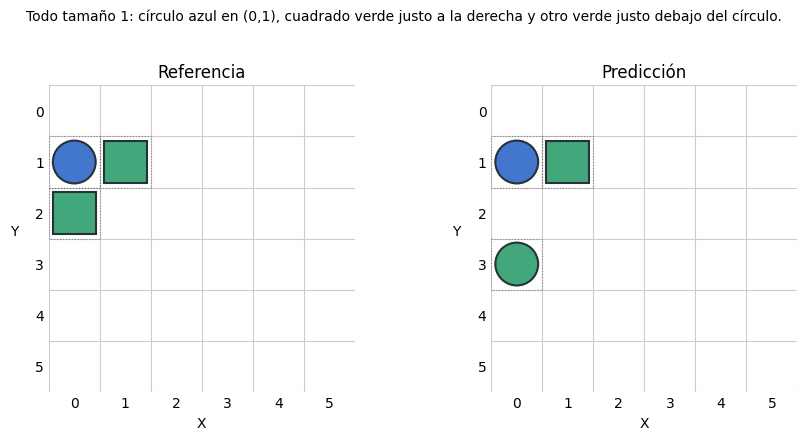

PROGRAMA ESPERADO:
CIRCLE BLUE 0 1 1
SQUARE GREEN 1 1 1
SQUARE GREEN 0 2 1

PROGRAMA GENERADO:
CIRCLE BLUE 0 1 1
SQUARE GREEN 1 1 1
CIRCLE GREEN 0 3 1

--- Ejemplo con error #2 ---


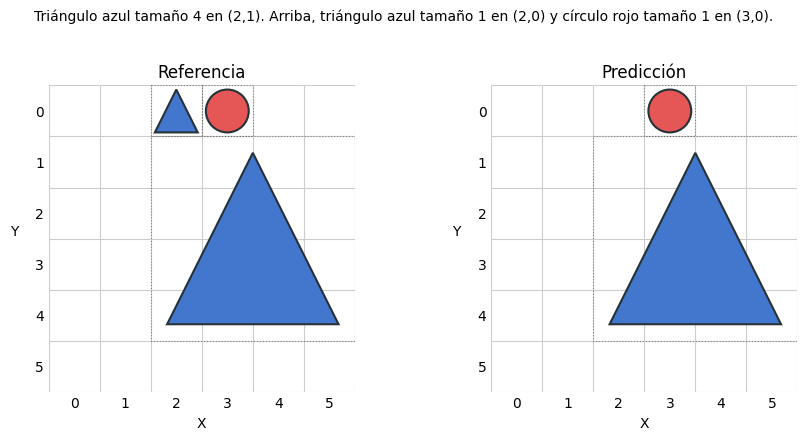

PROGRAMA ESPERADO:
TRIANGLE BLUE 2 0 1
CIRCLE RED 3 0 1
TRIANGLE BLUE 2 1 4

PROGRAMA GENERADO:
CIRCLE RED 3 0 1
TRIANGLE BLUE 2 1 4


In [23]:
# Generar predicciones con el modelo adaptado LoRA sobre el conjunto de desarrollo (dev_df)
from tqdm import auto as tqdm_auto
import pandas as pd

predictions_lora = []

print("Generando predicciones en 'dev' con el modelo adaptado con LoRA...")
for i in tqdm_auto.tqdm(range(dev_df.shape[0])):
    instruccion_actual = dev_df.iloc[i]['instruccion']

    # Usamos la misma estructura de mensajes que en el entrenamiento de LoRA
    messages = build_messages(instruccion_actual)

    # Generamos la respuesta con nuestro modelo adaptado
    programa_generado = generate_response(messages, max_new_tokens=96)
    predictions_lora.append(programa_generado)

# Evaluar los resultados
resultados_lora = evaluate_predictions(dev_df, predictions_lora)
show_metrics(resultados_lora, name='Fine-tuning con LoRA')

# Filtrar errores para análisis
errores_lora_idx = resultados_lora.index[~resultados_lora['exacto']].tolist()
print(f"Total de errores con LoRA: {len(errores_lora_idx)} de {len(dev_df)}")

# Visualizar dos ejemplos de error con el modelo adaptado
if len(errores_lora_idx) >= 2:
    print("\n--- Ejemplo con error #1 ---")
    compare_drawings(resultados_lora, index=errores_lora_idx[0])
    print("\n--- Ejemplo con error #2 ---")
    compare_drawings(resultados_lora, index=errores_lora_idx[1])
elif len(errores_lora_idx) >= 1:
    print("\n--- Ejemplo con error ---")
    compare_drawings(resultados_lora, index=errores_lora_idx[0])

**Resultados y comparación con prompting:**

Usando el modelo Finetuneado con LoRA:
Fine-tuning con LoRA (N = 120)
Validez:    100.0%
Accuracy:   98.3%
F1 objetos: 0.996

Solo encontro 2 errores en el modelado de los 120 casos del dataset dev.






---

### Evaluación final: test y test OOD

Una vez terminados los experimentos y seleccionada la mejor estrategia de prompting y realizado el fine-tuning LoRA, usando únicamente `dev`, realice las siguientes evaluaciones en orden:

1. **Test (dentro de distribución):** Evalúe ambas estrategias sobre los 120 ejemplos de `test_df`. Reporte validez, accuracy y F1 de objetos.

2. **Test OOD (fuera de distribución):** Evalúe ambas estrategias sobre los 50 ejemplos de `test_ood_df`. Reporte las mismas tres métricas.

Compare los resultados de ambas particiones y discuta las diferencias. ¿Los métodos generalizan bien a escenas diferentes?


In [24]:
# TODO: evaluar sobre test_df las dos estrategias seleccionadas usando
# exclusivamente los prompts, ejemplos e hiperparámetros elegidos en dev.
from contextlib import nullcontext
from peft import PeftModel

# Estrategia 4 Few shot usando ejemplos de Dataset de Training (con el modelo base, sin LoRA)
few_shot_examples_from_test = [
    {
        'instruccion': train_df.iloc[0]['instruccion'],
        'programa': train_df.iloc[0]['programa']
    },
    {
        'instruccion': train_df.iloc[1]['instruccion'],
        'programa': train_df.iloc[1]['programa']
    },
    {
        'instruccion': train_df.iloc[2]['instruccion'],
        'programa': train_df.iloc[2]['programa']
    }
]

test_llm_few_shot = []

# Si 'model' tiene adaptadores LoRA cargados, los desactivamos temporalmente para evaluar solo el modelo base
base_ctx = model.disable_adapter() if isinstance(model, PeftModel) else nullcontext()

with base_ctx:
    for i in range(test_df.shape[0]):
        instruccion_actual = test_df.iloc[i]['instruccion']
        messages = [
            {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO.
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo).
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
            {'role': 'user', 'content': few_shot_examples_from_test[0]['instruccion']},
            {'role': 'assistant', 'content': few_shot_examples_from_test[0]['programa']},
            {'role': 'user', 'content': few_shot_examples_from_test[1]['instruccion']},
            {'role': 'assistant', 'content': few_shot_examples_from_test[1]['programa']},
            {'role': 'user', 'content': few_shot_examples_from_test[2]['instruccion']},
            {'role': 'assistant', 'content': few_shot_examples_from_test[2]['programa']},
            {'role': 'user', 'content': instruccion_actual},
        ]
        programa_generado = generate_response(messages)
        test_llm_few_shot.append({
            'instruccion': instruccion_actual,
            'programa_generado': programa_generado,
        })

df_test_llm_few_shot = pd.DataFrame(test_llm_few_shot)
display(df_test_llm_few_shot)

resultados_test_few_shot = evaluate_predictions(test_df, df_test_llm_few_shot['programa_generado'])
show_metrics(resultados_test_few_shot, name='Test de Estrategia 4 (Few-Shot sin LoRA)')

,instruccion,programa_generado
0,"Círculo rojo tamaño 3 en (0,3).",CIRCLE RED 0 3 3
1,"En fila inicial 4 van triángulos amarillos, ta...",TRIANGLE YELLOW 0 3 1\nTRIANGLE YELLOW 0 4 2\n...
2,"Triángulo verde tamaño 3 desde (3,1).",TRIANGLE GREEN 3 1 3
3,"Sobre fila inicial 0, triángulo azul tamaño 2 ...",TRIANGLE BLUE 1 0 2\nSQUARE BLUE 3 0 2
4,"Un círculo azul tamaño 4 desde (0,2).",CIRCLE BLUE 0 2 4
...,...,...
115,"Cuadrado azul tamaño 3 en (1,1), círculo azul ...",SQUARE BLUE 1 1 3\nCIRCLE BLUE 3 4 2
116,"Poné un cuadrado amarillo tamaño 1 en (0,3). T...",SQUARE YELLOW 0 3 1\nCIRCLE RED 0 0 2\nCIRCLE ...
117,"Triángulo azul tamaño 3 en (0,2), círculo rojo...",TRIANGLE BLUE 0 2 3\nCIRCLE RED 3 2 1
118,"Sobre fila inicial 3, círculo verde tamaño 2 d...",CIRCLE GREEN 0 3 2\nTRIANGLE BLUE 0 2 1\nTRIAN...


Test de Estrategia 4 (Few-Shot sin LoRA) (N = 120)
Validez:    76.7%
Accuracy:   56.7%
F1 objetos: 0.633


Generando predicciones en 'test' con el modelo adaptado con LoRA...


  0%|          | 0/120 [00:00<?, ?it/s]

Fine-tuning con LoRA en test (N = 120)
Validez:    100.0%
Accuracy:   96.7%
F1 objetos: 0.982
Total de errores con LoRA en test: 4 de 120

--- Ejemplo con error #1 ---


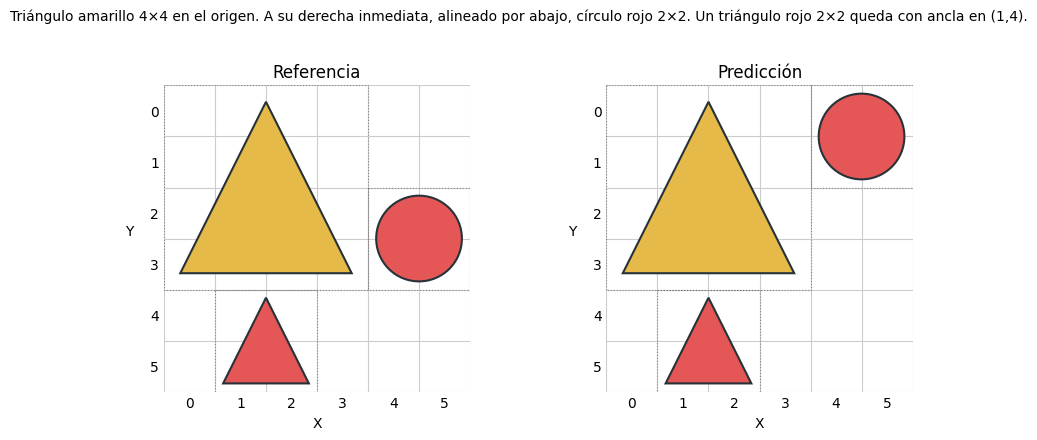

PROGRAMA ESPERADO:
TRIANGLE YELLOW 0 0 4
CIRCLE RED 4 2 2
TRIANGLE RED 1 4 2

PROGRAMA GENERADO:
TRIANGLE YELLOW 0 0 4
CIRCLE RED 4 0 2
TRIANGLE RED 1 4 2

--- Ejemplo con error #2 ---


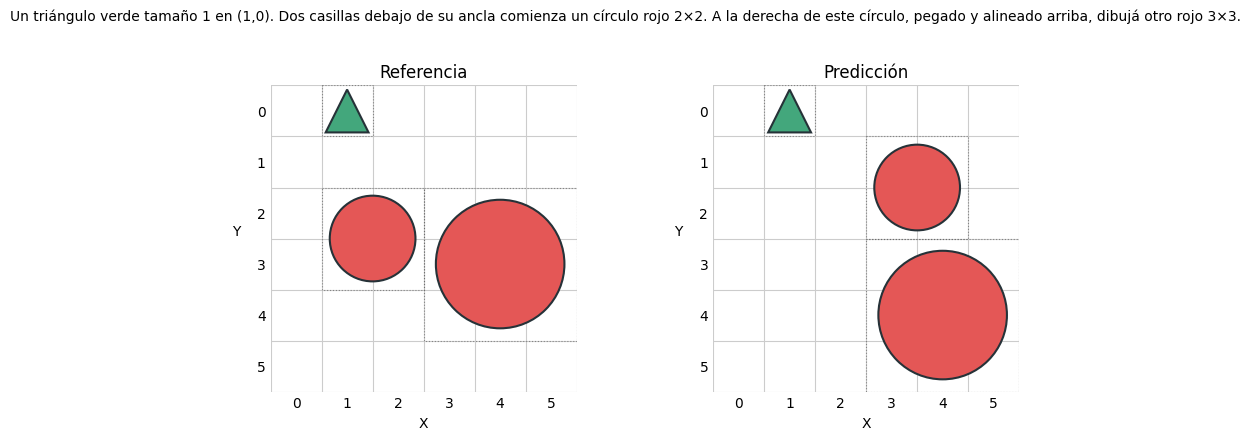

PROGRAMA ESPERADO:
TRIANGLE GREEN 1 0 1
CIRCLE RED 1 2 2
CIRCLE RED 3 2 3

PROGRAMA GENERADO:
TRIANGLE GREEN 1 0 1
CIRCLE RED 3 1 2
CIRCLE RED 3 3 3


In [25]:
# TODO: evaluar sobre test_df las con modelo Fine-tuned con LoRA


from tqdm import auto as tqdm_auto
import pandas as pd
from peft import PeftModel

LORA_DIR = "./modelo_con_lora"

# Asegurar que el modelo tenga los adaptadores LoRA cargados y activos
if not isinstance(model, PeftModel):
    if hasattr(model, "peft_config"):
        delattr(model, "peft_config")
    model = PeftModel.from_pretrained(model, LORA_DIR)
    model.eval()
    model.config.use_cache = True
else:
    model.enable_adapter_layers()
    model.eval()

predictions_lora_test = []

print("Generando predicciones en 'test' con el modelo adaptado con LoRA...")
for i in tqdm_auto.tqdm(range(test_df.shape[0])):
    instruccion_actual = test_df.iloc[i]['instruccion']

    # Usamos la misma estructura de mensajes que en el entrenamiento de LoRA
    messages = build_messages(instruccion_actual)

    # Generamos la respuesta con nuestro modelo adaptado
    programa_generado = generate_response(messages, max_new_tokens=96)
    predictions_lora_test.append(programa_generado)

# Evaluar los resultados
resultados_lora_test = evaluate_predictions(test_df, predictions_lora_test)
show_metrics(resultados_lora_test, name='Fine-tuning con LoRA en test')

# Filtrar errores para análisis
errores_lora_idx_test = resultados_lora_test.index[~resultados_lora_test['exacto']].tolist()
print(f"Total de errores con LoRA en test: {len(errores_lora_idx_test)} de {len(test_df)}")

# Visualizar dos ejemplos de error con el modelo adaptado
if len(errores_lora_idx_test) >= 2:
    print("\n--- Ejemplo con error #1 ---")
    compare_drawings(resultados_lora_test, index=errores_lora_idx_test[0])
    print("\n--- Ejemplo con error #2 ---")
    compare_drawings(resultados_lora_test, index=errores_lora_idx_test[1])
elif len(errores_lora_idx_test) >= 1:
    print("\n--- Ejemplo con error ---")
    compare_drawings(resultados_lora_test, index=errores_lora_idx_test[0])

**Test data set:**

Test de Estrategia 4 (Few-Shot sin LoRA) (N = 120)
Validez:    76.7%
Accuracy:   56.7%
F1 objetos: 0.633

Fine-tuning con LoRA en test (N = 120)
Validez:    100.0%
Accuracy:   96.7%
F1 objetos: 0.982
Total de errores con LoRA en test: 4 de 120

**Test_OOD data set:**

Test OOD de Estrategia 4 (Few-Shot sin LoRA) (N = 50)
Validez:    22.0%
Accuracy:   4.0%
F1 objetos: 0.101

Fine-tuning con LoRA en test_ood (N = 50)
Validez:    78.0%
Accuracy:   46.0%
F1 objetos: 0.628
Total de errores con LoRA en test_ood : 27 de 50


In [26]:
# TODO: evaluar sobre test_ood_df las dos estrategias seleccionadas usando
# exclusivamente los prompts, ejemplos e hiperparámetros elegidos en dev.
# Estrategia 4 Few shot usando ejemplos de Dataset de Training (con el modelo base, sin LoRA)
from contextlib import nullcontext
from peft import PeftModel

test_ood_llm_few_shot = []

# Si 'model' tiene adaptadores LoRA cargados, los desactivamos temporalmente para evaluar solo el modelo base
base_ctx = model.disable_adapter() if isinstance(model, PeftModel) else nullcontext()

with base_ctx:
    for i in range(test_ood_df.shape[0]):
        instruccion_actual = test_ood_df.iloc[i]['instruccion']
        messages = [
            {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO.
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo).
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
            {'role': 'user', 'content': few_shot_examples_from_test[0]['instruccion']},
            {'role': 'assistant', 'content': few_shot_examples_from_test[0]['programa']},
            {'role': 'user', 'content': few_shot_examples_from_test[1]['instruccion']},
            {'role': 'assistant', 'content': few_shot_examples_from_test[1]['programa']},
            {'role': 'user', 'content': few_shot_examples_from_test[2]['instruccion']},
            {'role': 'assistant', 'content': few_shot_examples_from_test[2]['programa']},
            {'role': 'user', 'content': instruccion_actual},
        ]
        programa_generado = generate_response(messages)
        test_ood_llm_few_shot.append({
            'instruccion': instruccion_actual,
            'programa_generado': programa_generado,
        })

df_test_ood_llm_few_shot = pd.DataFrame(test_ood_llm_few_shot)
display(df_test_ood_llm_few_shot)

resultados_test_ood_few_shot = evaluate_predictions(test_ood_df, df_test_ood_llm_few_shot['programa_generado'])
show_metrics(resultados_test_ood_few_shot, name='Test OOD de Estrategia 4 (Few-Shot sin LoRA)')

,instruccion,programa_generado
0,Hacé una casa de dos piezas: pared cuadrada az...,SQUARE BLUE 2 2 2\nTRIANGLE RED 2 2 2\nSQUARE ...
1,Quiero una cabaña verde con techo rojo. La par...,CIRCLE YELLOW 5 1 1\nTRIANGLE YELLOW 0 3 3\nTR...
2,Construí un faro con tres módulos de huella 2×...,CIRCLE YELLOW 2 2 2\nCIRCLE YELLOW 2 2 2\nCIRC...
3,Un pino de juguete: copa triangular verde tama...,TRIANGLE GREEN 1 0 3\nSQUARE RED 1 1 1\nCIRCLE...
4,"Para el árbol, colocá una copa circular verde ...",CIRCLE GREEN 1 0 3\nSQUARE RED 2 3 1\nSQUARE R...
5,"Armá un robot sobre un pedestal, sin brazos ni...",CIRCLE YELLOW 2 0 2\nCIRCLE BLUE 2 0 2\nCIRCLE...
6,Dibujá un cohete esquemático. La punta es un t...,CIRCLE YELLOW 1 0 1\nTRIANGLE RED 2 0 2\nCIRCL...
7,Me gustaría un globo aerostático reducido a en...,CIRCLE RED 1 0 3\nCIRCLE BLUE 2 3 1\nCIRCLE YE...
8,Hacé un autito con carrocería cuadrada azul ta...,CIRCLE BLUE 2 1 2\nCIRCLE RED 0 3 1\nCIRCLE RE...
9,Un vagón geométrico de tres piezas: caja cuadr...,CIRCLE BLUE 0 3 1\nCIRCLE BLUE 2 3 1\nCIRCLE B...


Test OOD de Estrategia 4 (Few-Shot sin LoRA) (N = 50)
Validez:    22.0%
Accuracy:   4.0%
F1 objetos: 0.101


Generando predicciones en 'test_ood' con el modelo adaptado con LoRA...


  0%|          | 0/50 [00:00<?, ?it/s]

Fine-tuning con LoRA en test_ood (N = 50)
Validez:    78.0%
Accuracy:   46.0%
F1 objetos: 0.628
Total de errores con LoRA en test_ood : 27 de 50

--- Ejemplo con error #1 ---


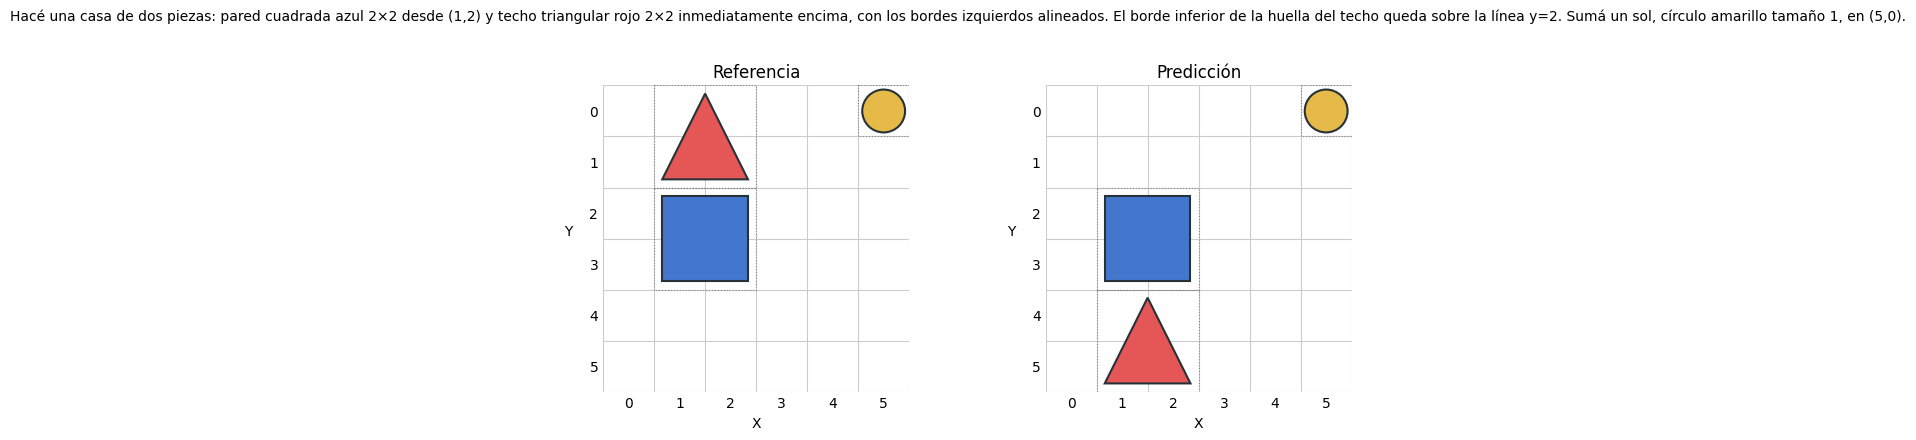

PROGRAMA ESPERADO:
TRIANGLE RED 1 0 2
CIRCLE YELLOW 5 0 1
SQUARE BLUE 1 2 2

PROGRAMA GENERADO:
CIRCLE YELLOW 5 0 1
SQUARE BLUE 1 2 2
TRIANGLE RED 1 4 2

--- Ejemplo con error #2 ---


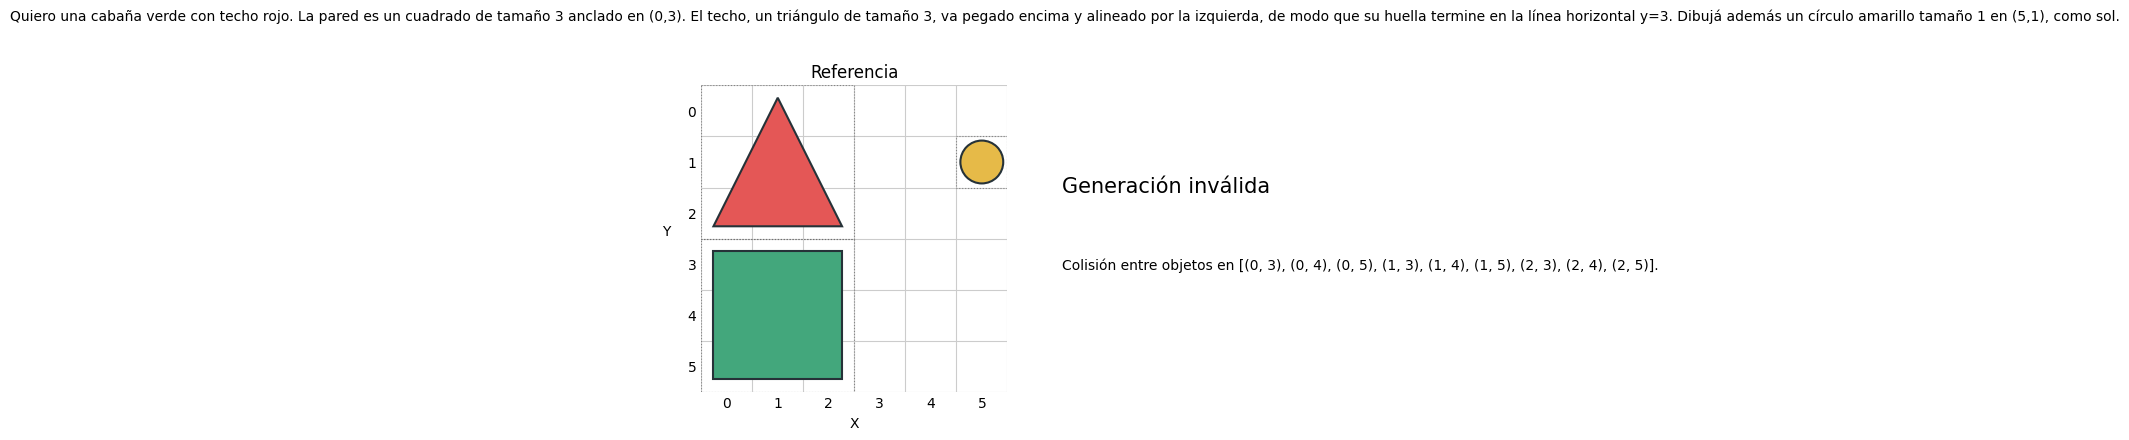

PROGRAMA ESPERADO:
TRIANGLE RED 0 0 3
CIRCLE YELLOW 5 1 1
SQUARE GREEN 0 3 3

PROGRAMA GENERADO:
CIRCLE YELLOW 5 1 1
SQUARE GREEN 0 3 3
TRIANGLE GREEN 0 3 3


In [27]:
# Evaluar sobre test_ood_df con el modelo Fine-tuned con LoRA
from tqdm import auto as tqdm_auto
import pandas as pd
from peft import PeftModel

LORA_DIR = "./modelo_con_lora"

# Asegurar que el modelo tenga los adaptadores LoRA cargados y activos
if not isinstance(model, PeftModel):
    if hasattr(model, "peft_config"):
        delattr(model, "peft_config")
    model = PeftModel.from_pretrained(model, LORA_DIR)
    model.eval()
    model.config.use_cache = True
else:
    model.enable_adapter_layers()
    model.eval()

predictions_lora_test_ood = []

print("Generando predicciones en 'test_ood' con el modelo adaptado con LoRA...")
for i in tqdm_auto.tqdm(range(test_ood_df.shape[0])):
    instruccion_actual = test_ood_df.iloc[i]['instruccion']

    # Usamos la misma estructura de mensajes que en el entrenamiento de LoRA
    messages = build_messages(instruccion_actual)

    # Generamos la respuesta con nuestro modelo adaptado
    programa_generado = generate_response(messages, max_new_tokens=96)
    predictions_lora_test_ood.append(programa_generado)

# Evaluar los resultados
resultados_lora_test_ood = evaluate_predictions(test_ood_df, predictions_lora_test_ood)
show_metrics(resultados_lora_test_ood, name='Fine-tuning con LoRA en test_ood')

# Filtrar errores para análisis
errores_lora_idx_test_ood = resultados_lora_test_ood.index[~resultados_lora_test_ood['exacto']].tolist()
print(f"Total de errores con LoRA en test_ood : {len(errores_lora_idx_test_ood)} de {len(test_ood_df)}")

# Visualizar dos ejemplos de error con el modelo adaptado
if len(errores_lora_idx_test_ood) >= 2:
    print("\n--- Ejemplo con error #1 ---")
    compare_drawings(resultados_lora_test_ood, index=errores_lora_idx_test_ood[0])
    print("\n--- Ejemplo con error #2 ---")
    compare_drawings(resultados_lora_test_ood, index=errores_lora_idx_test_ood[1])
elif len(errores_lora_idx_test_ood) >= 1:
    print("\n--- Ejemplo con error ---")
    compare_drawings(resultados_lora_test_ood, index=errores_lora_idx_test_ood[0])

### Análisis de resultados

Analice los resultados obtenidos y responda, al menos, las siguientes preguntas:

1. **¿Qué estrategia de prompting funcionó mejor?** Describa brevemente cómo se construyó, qué cambió respecto a zero-shot y qué resultados obtuvo.
2. **¿Qué aportó el fine-tuning con LoRA?** Compare los resultados con prompting, incluyendo las diferencias entre validez de DSL, accuracy y F1 de objetos.
3. **¿Qué diferencias aparecen entre `test` y `test_ood`?** Compare las tres métricas para cada estrategia. ¿Hay una caída de rendimiento? ¿Es similar para prompting y LoRA?
4. **¿En qué tipos de ejemplos OOD falla más el modelo?** Analice ejemplos concretos, tanto de escenas reales como de escenas con más de tres objetos.

**Sus respuestas aquí:**

1. la mejor estrategia fue la obtenida ajustando el modelo con LoRA seguido de la estratega 4 (few shot con casos del data set de train).
en cualquiera de las 2 estrategias guiamos al modelo base a efectuar el trabajo que buscabamos, y medimos su performance con las metricas relevantes para el trabajo.
2. LoRA ayudo al modelo base, ajustando un pequeño porcentaje de sus parametros, a realizar el trabajo que efectivamente nos interesa para la aplicacion. El costo computacional si bien es mayor al consumido por el modelo ajustado con few shot, obtiene resultados casi perfectos comparado con el segundo mejor.
3. En el data set de TEST, los resultados los resultados del modelo ajustado con few shot fueron muy buenos y aun mejores con el modelo tuneado con LoRA:
**Test data set:**

Test de Estrategia 4 (Few-Shot sin LoRA) (N = 120)
Validez:    76.7%
Accuracy:   56.7%
F1 objetos: 0.633

Fine-tuning con LoRA en test (N = 120)
Validez:    100.0%
Accuracy:   96.7%
F1 objetos: 0.982
Total de errores con LoRA en test: 4 de 120

Eso era esperable porque los casos a evaluar son muy parecidos a los usados en el post entrenamiento.

**Test_OOD data set:**

Test OOD de Estrategia 4 (Few-Shot sin LoRA) (N = 50)
Validez:    22.0%
Accuracy:   4.0%
F1 objetos: 0.101

Fine-tuning con LoRA en test_ood (N = 50)
Validez:    78.0%
Accuracy:   46.0%
F1 objetos: 0.628
Total de errores con LoRA en test_ood : 27 de 50

Y como era esperable los resultados con Test_ood fueron muy inferiores a los evidenciados con los ejemplos de test, para ambos modelos. Sin embargo LoRA performo de una manera mas robusta que la estrategia few-shot.

4. Las fallas en el modelado, se dan cuando la instruccion no hace referencia a las figuras geometricas directamente sino a "casa" o "cabaña" refiriendose a cuadrado debajo de triangulo. Eso, tal vez, con un modelo base mas amplio, podría haber mejorado.


